# Tópico 3 — Introdução à Avaliação Físico-Química de Proteínas

**Minicurso: Introdução à Biologia Computacional — da Genômica até a Estrutura Tridimensional**
14ª Semana de Biociências e Biotecnologia em Saúde · FIOCRUZ-PE / Instituto Aggeu Magalhães
*Protein Engineering and Structural Genomics* (PESG)

João Sartori · Michelly Lopes da Silva · Whendel Muniz dos Santos — Recife, 2026

---

No Tópico 1 extraímos a sequência da proteína **Envelope (E)** da Dengue; no Tópico 2 obtivemos
sua estrutura 3D. Agora a pergunta é: **o quão fisicamente favorável essa estrutura é, e como
medir o efeito de uma alteração nela?** Para isso usaremos o **PyRosetta**.

| Parte | Conteúdo | Proteína |
|---|---|---|
| **A** | `Pose`, função de score REF2015, minimização | Envelope (PDB 1OAN) |
| **B** | Modelagem de variantes e cálculo de **ΔΔG** | GB1 (PDB 1PGA) |
| **C** | Interface proteína–proteína (`InterfaceAnalyzerMover`) | Dímero da Envelope |

Todas as estruturas são visualizáveis **interativamente** no próprio notebook (Seção 0.3).

> ▶️ Execute as células em ordem. As marcadas com ⏱️ levam minutos.

---
# 0. Preparação do ambiente

## 0.1 Instalação

⏱️ **3–8 min** na primeira execução. Se o `import pyrosetta` falhar ao final, reinicie a sessão
(*Ambiente de execução → Reiniciar sessão*) e rode esta célula de novo.

📄 O PyRosetta é gratuito para uso **acadêmico**. Ver <https://els2.comotion.uw.edu/product/pyrosetta>.

In [2]:
import subprocess, sys

def _pip(*pacotes):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pacotes], check=True)

try:
    import pyrosetta
except ImportError:
    print("Instalando PyRosetta (alguns minutos)...")
    _pip("pyrosetta-installer")
    import pyrosetta_installer
    pyrosetta_installer.install_pyrosetta()
    import pyrosetta

try:
    import py3Dmol
except ImportError:
    _pip("py3Dmol")
    import py3Dmol

print("PyRosetta e py3Dmol prontos.")

Instalando PyRosetta (alguns minutos)...
Installing PyRosetta:
 os: ubuntu
 type: Release
 Rosetta C++ extras: 
 mirror: https://west.rosettacommons.org/pyrosetta/release/release
 extra packages: numpy

PyRosetta wheel url: https://:@west.rosettacommons.org/pyrosetta/release/release/PyRosetta4.Release.python313.ubuntu.wheel/pyrosetta-2026.39+release.49e05e797c-cp313-cp313-linux_x86_64.whl
PyRosetta e py3Dmol prontos.


## 0.2 Imports, paleta e inicialização

As *flags* do `init()`: ignoramos heteroátomos sem parâmetros (glicanos, ligantes), detectamos
pontes dissulfeto pela distância S–S e **fixamos a semente aleatória** para que a turma veja os
mesmos números.

> ⚠️ `-constant_seed` é para a aula. Em pesquisa, protocolos como o `FastRelax` são estocásticos
> e exigem **várias réplicas independentes**.

In [3]:
import os, time, tempfile, urllib.request
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Paleta: uma cor por papel semântico (azul/laranja = séries; azul/vermelho = sinal; cinzas = texto)
COR = {"serie1": "#2a78d6", "serie2": "#eb6834", "favoravel": "#2a78d6",
       "desfavoravel": "#e34948", "destaque": "#d03b3b", "tinta2": "#52514e",
       "suave": "#898781", "grade": "#e1e0d9", "eixo": "#c3c2b7"}

mpl.rcParams.update({
    "figure.facecolor": "#ffffff", "axes.facecolor": "#ffffff", "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": "#0b0b0b",
    "axes.labelcolor": COR["tinta2"], "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.edgecolor": COR["eixo"],
    "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": COR["suave"], "ytick.color": COR["suave"],
    "xtick.labelcolor": COR["tinta2"], "ytick.labelcolor": COR["tinta2"],
    "grid.color": COR["grade"], "grid.linewidth": 0.7,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

import pyrosetta, py3Dmol
pyrosetta.init(" ".join([
    "-ignore_unrecognized_res true",
    "-ignore_zero_occupancy false",
    "-detect_disulf true",
    "-constant_seed -jran 2026",
    "-mute core.import_pose core.io.pose_from_sfr core.conformation basic.io.database",
]))

scorefxn = pyrosetta.create_score_function("ref2015")
print("Função de score:", scorefxn.get_name())

┌───────────────────────────────────────────────────────────────────────────────┐
│                                  PyRosetta-4                                  │
│               Created in JHU by Sergey Lyskov and PyRosetta Team              │
│               (C) Copyright Rosetta Commons Member Institutions               │
│                                                                               │
│ NOTE: USE OF PyRosetta FOR COMMERCIAL PURPOSES REQUIRES PURCHASE OF A LICENSE │
│          See LICENSE.PyRosetta.md or email license@uw.edu for details         │
└───────────────────────────────────────────────────────────────────────────────┘
PyRosetta-4 2026 [Rosetta PyRosetta4.Release.python313.ubuntu 2026.39+release.49e05e797ca4383c6038f090e5db6c2593cb4963 2026-09-21T09:15:10] retrieved from: http://www.pyrosetta.org
core.init: Checking for fconfig files in pwd and ./rosetta/flags
core.init: Rosetta version: PyRosetta4.Release.python313.ubuntu r445 2026.39+release.49e05e797c 49

## 0.3 Módulo de visualização 3D

Funções que usaremos o notebook inteiro. As de estrutura abrem um visualizador **interativo**
(arraste para girar, role para aproximar) dentro da própria saída da célula.

| Função | Para quê |
|---|---|
| `ver(pose)` | a estrutura inteira, em *cartoon* |
| `ver(pose, destacar=[...])` | idem, com resíduos escolhidos em bastões e rotulados |
| `ver_sitio(pose, i)` | zoom na vizinhança do resíduo `i` |
| `ver_sobreposicao(p1, p2)` | duas estruturas sobrepostas, em cores diferentes |
| `mapa_pose()` | mapa do objeto `Pose`: o que ele guarda e como acessar cada parte |


In [4]:
def pose_para_pdb(pose):
    """Serializa um Pose como texto PDB (o que o py3Dmol consome)."""
    with tempfile.NamedTemporaryFile(suffix=".pdb", delete=False) as tmp:
        caminho = tmp.name
    pose.dump_pdb(caminho)
    texto = open(caminho).read()
    os.unlink(caminho)
    return texto


_CORES_CADEIA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def ver(pose, destacar=None, largura=740, altura=460, opacidade=1.0):
    """Cartoon da estrutura, uma cor por cadeia. `destacar`: lista de índices Rosetta."""
    vis = py3Dmol.view(width=largura, height=altura)
    vis.addModel(pose_para_pdb(pose), "pdb")
    vis.setStyle({"cartoon": {"color": "#c8c8c8", "opacity": opacidade}})

    info = pose.pdb_info()
    cadeias = sorted({info.chain(i) for i in range(1, pose.total_residue() + 1)})
    for cadeia, cor in zip(cadeias, _CORES_CADEIA):
        vis.setStyle({"chain": cadeia}, {"cartoon": {"color": cor, "opacity": opacidade}})

    for i in (destacar or []):
        sel = {"chain": info.chain(i), "resi": str(info.number(i))}
        vis.addStyle(sel, {"stick": {"colorscheme": "redCarbon", "radius": 0.22}})
        vis.addResLabels(sel, {"fontSize": 10, "backgroundOpacity": 0.7})

    vis.setBackgroundColor("white")
    vis.zoomTo()
    return vis.show()


def ver_sitio(pose, i, raio=8.0, largura=740, altura=460):
    """Zoom na vizinhança do resíduo `i`: ele em azul, os vizinhos em cinza."""
    info = pose.pdb_info()
    alvo = {"chain": info.chain(i), "resi": str(info.number(i))}

    vis = py3Dmol.view(width=largura, height=altura)
    vis.addModel(pose_para_pdb(pose), "pdb")
    vis.setStyle({"cartoon": {"color": "#d8d8d4", "opacity": 0.75}})
    vis.addStyle({"byres": True, "within": {"distance": raio, "sel": alvo}},
                 {"stick": {"colorscheme": "grayCarbon", "radius": 0.12}})
    vis.addStyle(alvo, {"stick": {"colorscheme": "blueCarbon", "radius": 0.26}})
    vis.addResLabels(alvo, {"fontSize": 12, "backgroundOpacity": 0.7})
    vis.setBackgroundColor("white")
    vis.zoomTo(alvo)
    return vis.show()


def ver_sobreposicao(pose_a, pose_b, rotulos=("A", "B"), largura=740, altura=460):
    """Duas estruturas no mesmo referencial: a primeira azul, a segunda laranja."""
    vis = py3Dmol.view(width=largura, height=altura)
    for pose, cor in ((pose_a, COR["serie1"]), (pose_b, COR["serie2"])):
        vis.addModel(pose_para_pdb(pose), "pdb")
    vis.setStyle({"model": 0}, {"cartoon": {"color": COR["serie1"]}})
    vis.setStyle({"model": 1}, {"cartoon": {"color": COR["serie2"]}})
    vis.setBackgroundColor("white")
    vis.zoomTo()
    print(f"azul = {rotulos[0]}   |   laranja = {rotulos[1]}")
    return vis.show()


def baixar_pdb(pdb_id):
    """Baixa do RCSB e devolve o caminho do arquivo limpo (sem águas/ligantes)."""
    from pyrosetta.toolbox import cleanATOM
    bruto = f"{pdb_id}.pdb"
    if not os.path.exists(bruto):
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id}.pdb", bruto)
    limpo = f"{pdb_id}.clean.pdb"
    if not os.path.exists(limpo):
        cleanATOM(bruto, out_file=limpo)
    return limpo



from matplotlib.patches import FancyBboxPatch

# Componentes do Pose: chave -> (título, descrição, como acessar, grupo)
_POSE_PARTES = {
    "residuos":    ("Resíduos",     "identidade, átomos\ne rotâmero",       "pose.residue(i)",   "conf"),
    "coordenadas": ("Coordenadas",  "x, y, z de\ncada átomo",              "res.xyz('CA')",     "conf"),
    "torcoes":     ("Torções",      "φ, ψ, ω (esqueleto)\nχ (cadeia lateral)", "pose.phi(i)",   "conf"),
    "secstruct":   ("Estrutura 2ª", "H / E / L\npor resíduo",              "pose.secstruct()",  "conf"),
    "foldtree":    ("FoldTree",     "como as cadeias se\nconectam (jumps)", "pose.fold_tree()", "conf"),
    "pdbinfo":     ("PDBInfo",      "numeração PDB ↔\nRosetta e cadeias",   "pose.pdb_info()",   "pdb"),
    "energias":    ("Energies",     "último score: por\ntermo e por resíduo", "pose.energies()", "ener"),
}
_ESTILO_MAPA = {  # (preenchimento, borda, tinta)
    "neutro": ("#ffffff", "#c3c2b7", "#0b0b0b"),
    "le":     ("#e3edfa", "#2a78d6", "#0b0b0b"),
    "muda":   ("#fdeae1", "#eb6834", "#0b0b0b"),
    "fora":   ("#f6f6f3", "#e8e7e1", "#b5b3ab"),
}


def mapa_pose(le=(), muda=(), titulo=None):
    """Desenha o mapa do objeto Pose.

    Sem argumentos: o mapa completo, com descrições.
    Com `le` / `muda`: versão compacta, destacando o que o bloco LÊ (azul)
    e o que ele MODIFICA (laranja) no Pose.
    """
    le, muda = set(le), set(muda)
    desconhecidas = (le | muda) - set(_POSE_PARTES)
    if desconhecidas:
        raise ValueError(f"Partes desconhecidas: {desconhecidas}. Use: {list(_POSE_PARTES)}")
    completo = not (le or muda)
    altura = 3.0 if completo else 1.75

    fig, ax = plt.subplots(figsize=(11, altura))
    ax.set_xlim(0, 100); ax.set_ylim(0, 30 if completo else 18); ax.axis("off")
    topo = 30 if completo else 18

    # Moldura externa do Pose e grupo Conformation
    ax.add_patch(FancyBboxPatch((0.3, 0.3), 99.4, topo - 0.6, boxstyle="round,pad=0,rounding_size=1.2",
                                facecolor="#fbfbf9", edgecolor=COR["eixo"], linewidth=1.0))
    ax.text(1.6 if completo else 72.5, topo - 2.2, "Pose", fontsize=12, fontweight="bold", va="top", color="#0b0b0b")
    larg, gap, y0 = 13.0, 0.8, 1.6
    h_caixa = 20.0 if completo else 10.6
    ax.add_patch(FancyBboxPatch((1.2, y0 - 0.8), 5 * larg + 4 * gap + 1.6, h_caixa + 4.6,
                                boxstyle="round,pad=0,rounding_size=1.0", facecolor="none",
                                edgecolor=COR["eixo"], linewidth=0.8, linestyle=(0, (3, 2))))
    ax.text(2.0, y0 + h_caixa + 2.6, "Conformation", fontsize=9, color=COR["tinta2"],
            va="center", fontstyle="italic")

    x = 2.0
    for chave, (nome, desc, acesso, grupo) in _POSE_PARTES.items():
        if grupo != "conf" and x < 72:
            x = 72.5                      # PDBInfo e Energies ficam fora da Conformation
        estado = ("neutro" if completo else
                  "muda" if chave in muda else "le" if chave in le else "fora")
        fundo, borda, tinta = _ESTILO_MAPA[estado]
        ax.add_patch(FancyBboxPatch((x, y0), larg, h_caixa, boxstyle="round,pad=0,rounding_size=0.8",
                                    facecolor=fundo, edgecolor=borda,
                                    linewidth=1.8 if estado in ("le", "muda") else 1.0))
        cx = x + larg / 2
        if completo:
            ax.text(cx, y0 + h_caixa - 3.2, nome, ha="center", fontsize=9.5, fontweight="bold", color=tinta)
            ax.text(cx, y0 + h_caixa / 2, desc, ha="center", va="center", fontsize=7.6,
                    color=COR["tinta2"], linespacing=1.35)
            ax.text(cx, y0 + 2.6, acesso, ha="center", fontsize=7.4, family="monospace", color=tinta)
        else:
            ax.text(cx, y0 + h_caixa - 3.6, nome, ha="center", fontsize=9.5, fontweight="bold", color=tinta)
            ax.text(cx, y0 + 2.2, acesso, ha="center", fontsize=7.4, family="monospace", color=tinta)
            if estado in ("le", "muda"):   # rótulo textual: o estado não depende só da cor
                ax.text(cx, y0 + h_caixa / 2 - 0.4, "lê" if estado == "le" else "modifica",
                        ha="center", va="center", fontsize=7.4, color=borda, fontweight="bold")
        x += larg + gap

    if titulo is None:
        titulo = ("O que há dentro de um Pose" if completo
                  else "Partes do Pose usadas neste bloco")
    ax.set_title(titulo, loc="left", fontsize=11 if not completo else 12, pad=6)
    plt.tight_layout(pad=0.4); plt.show()


print("Módulo de visualização carregado.")

Módulo de visualização carregado.


---
---
# Parte A — `Pose`, função de score e minimização

## A.1 Carregando e limpando a estrutura

Usaremos a estrutura **experimental** do ectodomínio da proteína E da Dengue-2:
**PDB [1OAN](https://www.rcsb.org/structure/1OAN)** (raios X, Modis *et al.*, 2003). Ela contém
o **homodímero** (cadeias A e B) — o dímero volta na Parte C.

Um PDB cru não é um modelo pronto para simulação: traz águas, glicanos (`NAG`, `BMA`, `FUC`),
íons e confôrmeros alternativos. `cleanATOM` (dentro de `baixar_pdb`) mantém só as linhas `ATOM`.

> ⚠️ Limpeza mínima ≠ preparação completa. Descartar um **cofator funcional** é um erro
> silencioso: o cálculo roda e o resultado é biologicamente errado.

> 🔁 **Sua própria estrutura:** troque a linha abaixo por
> `arquivo = "meu_modelo_alphafold.pdb"` — o resto do notebook funciona igual.

In [15]:
arquivo = baixar_pdb("1OAN")
pose_dimero = pyrosetta.pose_from_file(arquivo)

print(f"Resíduos: {pose_dimero.total_residue()}   Cadeias: {pose_dimero.num_chains()}")
ver(pose_dimero)

Resíduos: 788   Cadeias: 2


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## A.2 O objeto `Pose` e a numeração

O **`Pose`** é o estado completo do sistema: sequência, coordenadas, geometria interna (ângulos
φ/ψ/χ), energias e o mapa para a numeração do PDB. A figura abaixo mostra as partes e como
acessar cada uma. A maior parte vive dentro da **`Conformation`** (a geometria); `PDBInfo` e
`Energies` são anexos.

Duas regras que evitam a maioria dos erros de iniciante:

1. **Operações modificam o `Pose` no lugar.** Use `clone()` antes de mexer.
2. **A numeração Rosetta é contínua de 1 a N**, ignorando letras de cadeia e lacunas do PDB.
   Converta com `pdb2pose` **no momento do uso** — e trate o retorno `0`, que significa
   "não existe neste `Pose`".

In [ ]:
mapa_pose()   # o mapa completo do objeto Pose

In [17]:
pose = pose_dimero.split_by_chain(1)   # monômero, cadeia A
pose_original = pose.clone()           # referência intocada
info = pose.pdb_info()

print(f"Monômero: {pose.total_residue()} resíduos")
print(f"Sequência: {pose.sequence()[:50]}...\n")

# Numeração nos dois sentidos
i = info.pdb2pose("A", 100)
print(f"PDB A:100  ->  Rosetta {i}  ->  PDB {info.chain(i)}:{info.number(i)} ({pose.residue(i).name3()})")

# No dímero a numeração atravessa as cadeias — veja o salto:
d = pose_dimero.pdb_info()
for j in (1, pose.total_residue(), pose.total_residue() + 1, pose_dimero.total_residue()):
    print(f"  dímero: Rosetta {j:>4} = PDB {d.chain(j)}:{d.number(j)}")

Monômero: 394 resíduos
Sequência: MRCIGISNRDFVEGVSGGSWVDIVLEHGSCVTTMAKNKPTLDFELIKTEA...

PDB A:100  ->  Rosetta 100  ->  PDB A:100 (GLY)
  dímero: Rosetta    1 = PDB A:1
  dímero: Rosetta  394 = PDB A:394
  dímero: Rosetta  395 = PDB B:1
  dímero: Rosetta  788 = PDB B:394


In [7]:
# Interrogando um resíduo: identidade, torções e coordenadas

res = pose.residue(i)
print(f"Resíduo A:100 = {res.name3()} ({res.name1()}) | {res.natoms()} átomos | {res.nchi()} ângulos χ")
print(f"  phi={pose.phi(i):7.1f}  psi={pose.psi(i):7.1f}  omega={pose.omega(i):7.1f}")
for k in range(1, res.nchi() + 1):
    print(f"  chi{k}={pose.chi(k, i):7.1f}")
ca = res.xyz("CA")
print(f"  Cα: ({ca.x:.2f}, {ca.y:.2f}, {ca.z:.2f})")

# Estrutura secundária (DSSP). A proteína E é uma proteína de fusão classe II: rica em folhas β.
from pyrosetta.rosetta.core.scoring.dssp import Dssp
Dssp(pose).insert_ss_into_pose(pose)
ss = pose.secstruct()
print("\nEstrutura secundária:", {t: f"{ss.count(t)/len(ss):.0%}"
                                 for t in "HEL"}, " (H=hélice, E=fita, L=alça)")

Resíduo A:100 = GLY (G) | 7 átomos | 0 ângulos χ
  phi=  178.0  psi= -172.3  omega=  179.6
  Cα: (-14.32, 81.75, -16.00)

Estrutura secundária: {'H': '6%', 'E': '46%', 'L': '47%'}  (H=hélice, E=fita, L=alça)


## A.3 A função de score REF2015

Uma função de score recebe uma conformação e devolve um número: quanto **menor**, mais
favorável. A REF2015 soma termos ponderados — van der Waals (`fa_atr`/`fa_rep`), solvatação
(`fa_sol`), eletrostática (`fa_elec`), ligações de hidrogênio (`hbond_*`), penalidades de
rotâmero (`fa_dun`) e de Ramachandran (`rama_prepro`), entre outros.

**Três limitações para levar deste tópico:**

1. A unidade é **REU**, *não* kcal/mol — não há fator de conversão exato.
2. O **valor absoluto diz pouco**: depende do tamanho e da composição. Só **diferenças entre
   poses equivalentes** são interpretáveis.
3. É uma energia livre **aproximada e empírica** de uma **única** conformação — não amostra
   entropia conformacional.

### Os termos da REF2015

Cada linha da tabela é um termo que o Rosetta calcula e soma, multiplicado pelo seu **peso**.
São esses mesmos nomes (`fa_atr`, `fa_sol`, `rama_prepro`...) que aparecem na decomposição do
score logo abaixo.

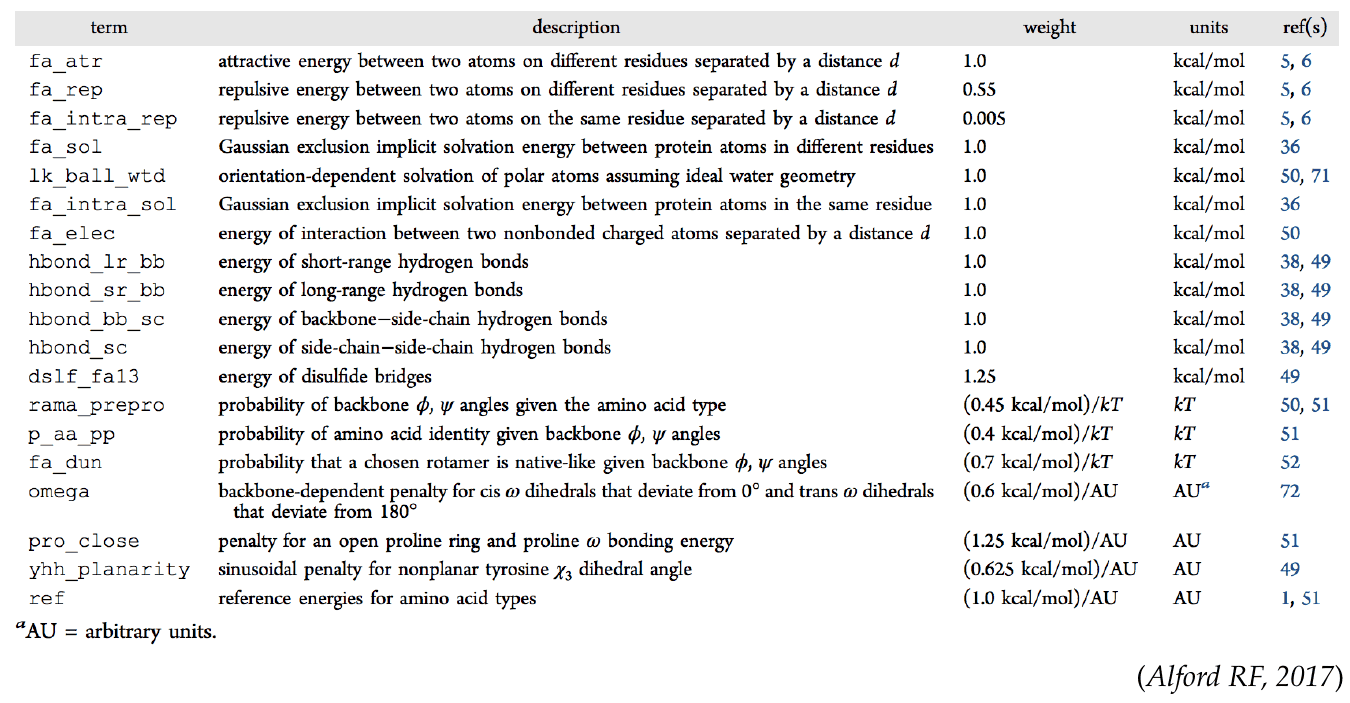

Os termos se dividem em dois grupos. Os **baseados em física** (amarelo) descrevem interações entre
átomos: van der Waals, solvatação, eletrostática, ligações de hidrogênio e pontes dissulfeto. Os
**baseados em conhecimento** (verde) são estatísticas tiradas de estruturas experimentais do PDB:
quão comuns são aqueles ângulos φ/ψ, aquele rotâmero, aquele aminoácido. É por isso que alguns
pesos estão em kcal/mol e outros em *kT* ou unidades arbitrárias.

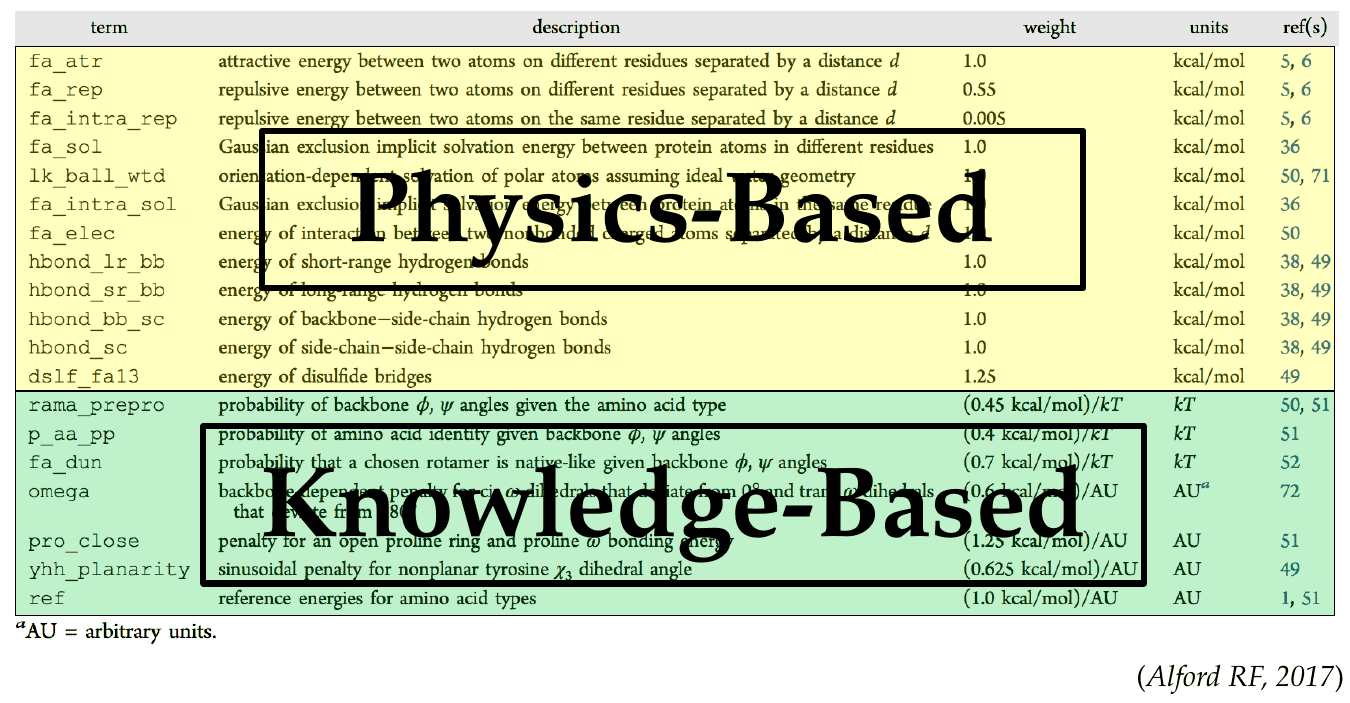

<sub>Figuras: slides 11–12 de *Rosetta Energy Function*, Meiler Lab
(<https://meilerlab.org/wp-content/uploads/2023/12/Rosetta_Energy_Function.pdf>), adaptados de
ALFORD *et al.*, *J. Chem. Theory Comput.* 13, 3031–3048, 2017. Na tabela original, as descrições de
`hbond_lr_bb` e `hbond_sr_bb` aparecem trocadas: `sr` = *short-range*, `lr` = *long-range*.</sub>


In [8]:
total = scorefxn(pose)
print(f"Score total: {total:,.1f} REU   ({total/pose.total_residue():.2f} REU/resíduo)")

# De onde vem esse número: contribuição = peso x valor bruto
energias, pesos = pose.energies().total_energies(), scorefxn.weights()
termos = pd.DataFrame([
    {"termo": str(st), "peso": pesos[st], "bruto": energias[st],
     "contribuicao_REU": pesos[st] * energias[st]}
    for st in scorefxn.get_nonzero_weighted_scoretypes()
]).sort_values("contribuicao_REU").reset_index(drop=True)

print(f"Soma das contribuições: {termos['contribuicao_REU'].sum():,.1f} REU (confere com o total)")
termos.round(2)

core.scoring.elec.util: Read 40 countpair representative atoms
core.pack.dunbrack.RotamerLibrary: shapovalov_lib_fixes_enable option is true.
core.pack.dunbrack.RotamerLibrary: shapovalov_lib::shap_dun10_smooth_level of 1( aka lowest_smooth ) got activated.
core.pack.dunbrack.RotamerLibrary: Binary rotamer library selected: /usr/local/lib/python3.13/dist-packages/pyrosetta/database/rotamer/shapovalov/StpDwn_0-0-0/Dunbrack10.lib.bin
core.pack.dunbrack.RotamerLibrary: Using Dunbrack library binary file '/usr/local/lib/python3.13/dist-packages/pyrosetta/database/rotamer/shapovalov/StpDwn_0-0-0/Dunbrack10.lib.bin'.
core.pack.dunbrack.RotamerLibrary: Dunbrack 2010 library took 0.237167 seconds to load from binary
Score total: 1,439.2 REU   (3.65 REU/resíduo)
Soma das contribuições: 1,439.2 REU (confere com o total)


,termo,peso,bruto,contribuicao_REU
0,ScoreType.fa_atr,1.00,-2148.47,-2148.47
1,ScoreType.fa_elec,1.00,-412.82,-412.82
2,ScoreType.hbond_lr_bb,1.00,-119.51,-119.51
3,ScoreType.hbond_sr_bb,1.00,-34.97,-34.97
4,ScoreType.p_aa_pp,0.60,-56.56,-33.93
5,ScoreType.lk_ball_wtd,1.00,-32.53,-32.53
6,ScoreType.hbond_bb_sc,1.00,-25.77,-25.77
7,ScoreType.hbond_sc,1.00,-15.65,-15.65
8,ScoreType.dslf_fa13,1.25,-6.79,-8.49
9,ScoreType.omega,0.40,-0.56,-0.22


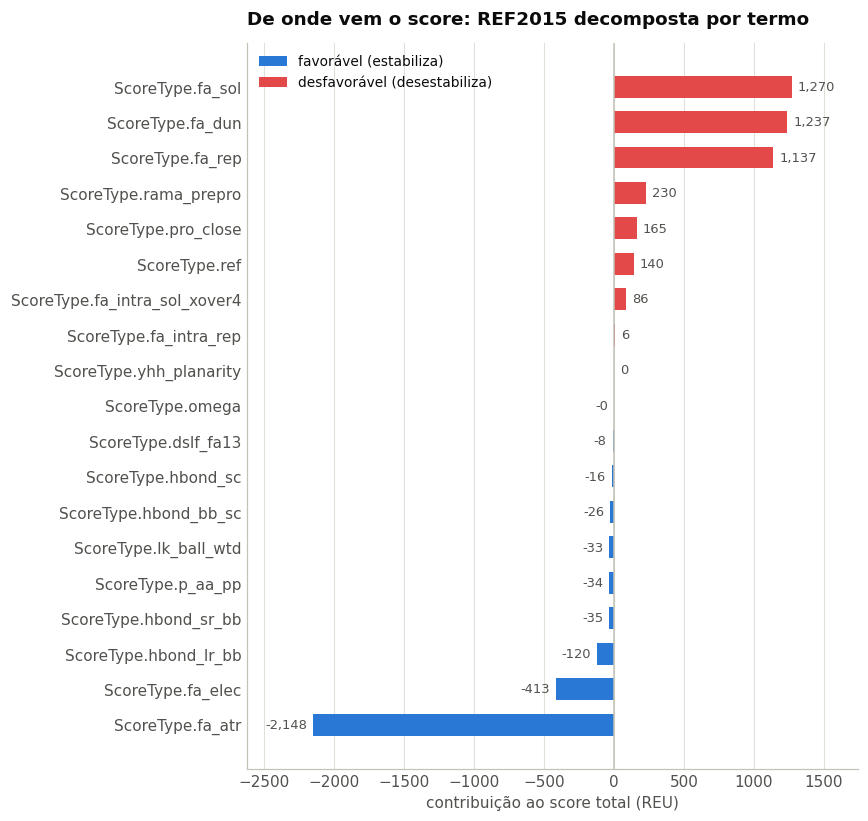

In [9]:
# A cor codifica o SINAL da contribuição, não a identidade do termo.
dados = termos.sort_values("contribuicao_REU")
faixa = dados["contribuicao_REU"].abs().max()

fig, ax = plt.subplots(figsize=(8, 0.33 * len(dados) + 1.3))
ax.barh(dados["termo"], dados["contribuicao_REU"], height=0.62, linewidth=0,
        color=[COR["favoravel"] if v < 0 else COR["desfavoravel"]
               for v in dados["contribuicao_REU"]])
for y, v in enumerate(dados["contribuicao_REU"]):
    ax.text(v + (faixa * 0.02 if v >= 0 else -faixa * 0.02), y, f"{v:,.0f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=COR["tinta2"])

ax.axvline(0, color=COR["eixo"], linewidth=1.0)
ax.set_xlim(dados["contribuicao_REU"].min() - faixa * 0.22,
            dados["contribuicao_REU"].max() + faixa * 0.22)
ax.set_xlabel("contribuição ao score total (REU)")
ax.set_title("De onde vem o score: REF2015 decomposta por termo")
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.legend(handles=[Patch(facecolor=COR["favoravel"], label="favorável (estabiliza)"),
                   Patch(facecolor=COR["desfavoravel"], label="desfavorável (desestabiliza)")],
          loc="upper left")
plt.tight_layout(); plt.show()

> 💡 `fa_atr` e `fa_rep` são tipicamente os dois maiores termos, em sinais opostos: empacotamento
> é o equilíbrio entre "juntar o máximo possível" e "não sobrepor". Um `fa_rep` desproporcional é
> a assinatura de **choques estéricos**. Já `ref` é uma energia de **referência** por tipo de
> aminoácido — calibração, não interação física; não a interprete fisicamente.

### Energia por resíduo: o diagnóstico mais útil

Desagregar o score por resíduo localiza *onde* a estrutura está tensionada.

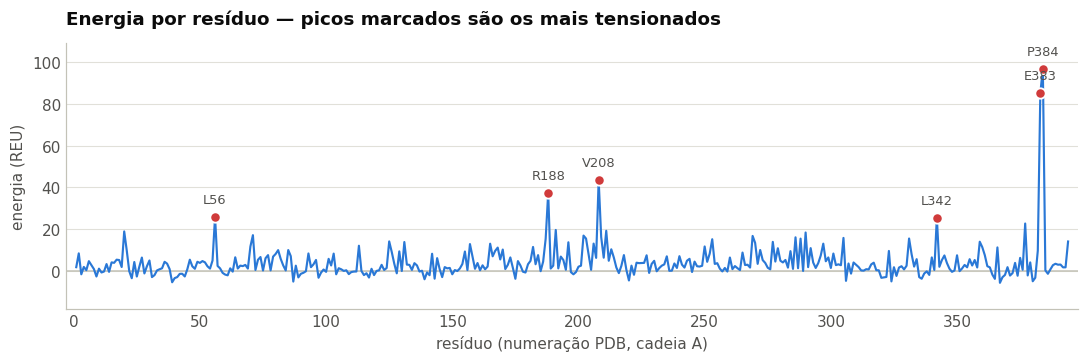

 rosetta  pdb aa   energia
     384  384  P 96.808356
     383  383  E 85.047094
     208  208  V 43.547590
     188  188  R 37.393456
      56   56  L 25.932362
     342  342  L 25.574317


In [10]:
scorefxn(pose)
por_residuo = pd.DataFrame({
    "rosetta": range(1, pose.total_residue() + 1),
    "pdb": [info.number(k) for k in range(1, pose.total_residue() + 1)],
    "aa": [pose.residue(k).name1() for k in range(1, pose.total_residue() + 1)],
    "energia": [pose.energies().residue_total_energy(k)
                for k in range(1, pose.total_residue() + 1)],
})
piores = por_residuo.nlargest(6, "energia")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axhline(0, color=COR["eixo"], linewidth=1.0)
ax.plot(por_residuo["pdb"], por_residuo["energia"], color=COR["serie1"], linewidth=1.4)
ax.scatter(piores["pdb"], piores["energia"], s=46, color=COR["destaque"],
           zorder=3, edgecolor="#ffffff", linewidth=1.2)
for _, r in piores.iterrows():
    ax.annotate(f'{r["aa"]}{r["pdb"]}', xy=(r["pdb"], r["energia"]), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8.5, color=COR["tinta2"])

ax.set_xlabel("resíduo (numeração PDB, cadeia A)"); ax.set_ylabel("energia (REU)")
ax.set_title("Energia por resíduo — picos marcados são os mais tensionados")
ax.yaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.margins(x=0.01, y=0.12)
plt.tight_layout(); plt.show()

print(piores.to_string(index=False))

In [11]:
# Onde esses resíduos estão na estrutura? (bastões vermelhos)
ver(pose, destacar=list(piores["rosetta"]))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

> 💡 **Antes de culpar a biologia, suspeite da preparação.** Em uma estrutura **recém-importada**,
> energias altas quase sempre refletem hidrogênios recém-adicionados fora de posição e rotâmeros
> ligeiramente fora dos mínimos do Rosetta — não regiões genuinamente frustradas. A leitura só
> fica confiável **depois** da minimização.

## A.4 Minimização

A estrutura importada é um ponto na superfície de energia, mas **não um mínimo dela**. Comparar
scores de estruturas não minimizadas é comparar ruído. Regra: **minimize antes de comparar**.

| | `MinMover` | `FastRelax` |
|---|---|---|
| O que faz | minimização por gradiente nas torções | ciclos de *repacking* + minimização |
| Natureza | determinística | estocástica (Monte Carlo) |
| Muda rotâmeros? | não | **sim** |
| Custo | segundos | minutos |

Ambos são governados por um **`MoveMap`**, uma máscara sobre os graus de liberdade
(`set_bb`, `set_chi`, `set_jump`). Estratégia segura: **desligue tudo e depois libere só o que
quer** — um `MoveMap` novo permite tudo, e "permitir tudo por esquecimento" é fonte comum de
resultados inexplicáveis.

In [13]:
from pyrosetta.rosetta.core.kinematics import MoveMap
from pyrosetta.rosetta.protocols.minimization_packing import MinMover
from pyrosetta.rosetta.core.scoring import CA_rmsd

mm = MoveMap()
mm.set_bb(True); mm.set_chi(True); mm.set_jump(False)

min_mover = MinMover(mm, scorefxn, "lbfgs_armijo_nonmonotone", 0.01, True)

pose_min = pose_original.clone()
antes = scorefxn(pose_min)
t0 = time.time(); min_mover.apply(pose_min); dt = time.time() - t0
depois = scorefxn(pose_min)

print(f"Score: {antes:>10,.1f}  ->  {depois:>10,.1f} REU   (Δ = {depois-antes:,.1f})")
print(f"RMSD Cα vs. original: {CA_rmsd(pose_original, pose_min):.3f} Å")
print(f"Tempo: {dt:.1f} s")

core.optimization.LineMinimizer: Inaccurate G in step= 9.53674e-09 Deriv= -1800.03 Finite Diff= 1.4521e+09
core.optimization.LineMinimizer: Inaccurate G in step= 5.30282e-09 Deriv= -21652.6 Finite Diff= 2.57904e+09
core.optimization.LineMinimizer: Inaccurate G in step= 5.53543e-09 Deriv= -20474.7 Finite Diff= 2.50172e+09
core.optimization.LineMinimizer: Inaccurate G in step= 2.22015e-08 Deriv= -118091 Finite Diff= 6.23633e+08
core.optimization.Minimizer: Line search failed even after resetting Hessian; aborting at iter#169
Score:    1,439.2  ->      -402.1 REU   (Δ = -1,841.3)
RMSD Cα vs. original: 0.776 Å
Tempo: 30.2 s


> 💡 **Grande queda de energia, pequeno deslocamento.** Centenas de REU com RMSD de Cα bem abaixo
> de 1 Å. Essa é a lição central: a maior parte da "má energia" de uma estrutura importada está em
> **detalhes locais de geometria**, não na dobra. Por isso **sempre reporte o RMSD junto da
> energia** — uma queda grande com RMSD grande é sinal de que a estrutura se deformou para agradar
> à função de score.

In [14]:
ver_sobreposicao(pose_original, pose_min, rotulos=("importada", "minimizada"))

azul = importada   |   laranja = minimizada


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### `FastRelax` restrito a uma região

O `FastRelax` alterna *repacking* e minimização em vários ciclos, variando o peso do termo
repulsivo. Na proteína inteira leva muitos minutos; vamos restringi-lo à **alça de fusão
(98–110)**, um segmento muito conservado na ponta do domínio II. Isso é rápido *e* introduz o
**relaxamento local**, base metodológica da Parte B.

> ⚠️ **Armadilha clássica:** o `MoveMap` controla apenas a **minimização contínua**. O `FastRelax`
> *também* faz *repacking* — uma busca **discreta** de rotâmeros governada por um `PackerTask`,
> que por padrão acontece na proteína **inteira**. Para congelar cadeias laterais distantes é
> preciso uma `TaskFactory`; é exatamente o que faremos na Parte B.

In [ ]:
# ⏱️ 1-4 minutos

from pyrosetta.rosetta.protocols.relax import FastRelax

liberados = [j for j in (info.pdb2pose("A", n) for n in range(94, 115)) if j != 0]

mm_local = MoveMap()
mm_local.set_bb(False); mm_local.set_chi(False); mm_local.set_jump(False)
for j in liberados:
    mm_local.set_bb(j, True); mm_local.set_chi(j, True)

relax = FastRelax(scorefxn, 1)      # 1 repetição (produção usa >= 3)
relax.set_movemap(mm_local)

pose_relax = pose_original.clone()
t0 = time.time(); relax.apply(pose_relax); dt = time.time() - t0

print(f"Liberados {len(liberados)} de {pose.total_residue()} resíduos")
antes_relax, depois_relax = scorefxn(pose_original), scorefxn(pose_relax)
print(f"Score: {antes_relax:,.1f}  ->  {depois_relax:,.1f} REU   (Δ = {depois_relax-antes_relax:+,.1f})")
print(f"RMSD Cα: {CA_rmsd(pose_original, pose_relax):.3f} Å  |  {dt:.1f} s")

protocols.relax.RelaxScriptManager: Reading relax scripts list from database.
protocols.relax.RelaxScriptManager: Looking for MonomerRelax2019.txt
protocols.relax.RelaxScriptManager: ================== Reading script file: /usr/local/lib/python3.13/dist-packages/pyrosetta/database/sampling/relax_scripts/MonomerRelax2019.txt ==================
protocols.relax.RelaxScriptManager: repeat %%nrepeats%%
protocols.relax.RelaxScriptManager: coord_cst_weight 1.0
protocols.relax.RelaxScriptManager: scale:fa_rep 0.040
protocols.relax.RelaxScriptManager: repack
protocols.relax.RelaxScriptManager: scale:fa_rep 0.051
protocols.relax.RelaxScriptManager: min 0.01
protocols.relax.RelaxScriptManager: coord_cst_weight 0.5
protocols.relax.RelaxScriptManager: scale:fa_rep 0.265
protocols.relax.RelaxScriptManager: repack
protocols.relax.RelaxScriptManager: scale:fa_rep 0.280
protocols.relax.RelaxScriptManager: min 0.01
protocols.relax.RelaxScriptManager: coord_cst_weight 0.0
protocols.relax.RelaxScriptManag

### Antes × depois do `FastRelax` local: onde a energia mudou?

O score total resume tudo em um número. Para entender o que o relaxamento fez, compare as
energias **antes** (estrutura importada) e **depois** do `FastRelax`: primeiro por **termo** da
REF2015, depois por **resíduo**.

In [ ]:
# Antes x depois do FastRelax local: de onde veio a queda de energia?

def contribuicoes(p):
    """Contribuição (peso x valor bruto) de cada termo da REF2015 para o score de p."""
    scorefxn(p)
    e, w = p.energies().total_energies(), scorefxn.weights()
    return {str(st): w[st] * e[st] for st in scorefxn.get_nonzero_weighted_scoretypes()}

pre, pos = contribuicoes(pose_original), contribuicoes(pose_relax)
comp_relax = pd.DataFrame({"termo": list(pre),
                           "antes_REU": list(pre.values()),
                           "depois_REU": [pos[t] for t in pre]})
comp_relax["delta_REU"] = comp_relax["depois_REU"] - comp_relax["antes_REU"]
comp_relax = comp_relax.sort_values("delta_REU").reset_index(drop=True)

print(f"Total: {comp_relax['antes_REU'].sum():,.1f}  ->  {comp_relax['depois_REU'].sum():,.1f} REU"
      f"   (Δ = {comp_relax['delta_REU'].sum():+,.1f})\n")
print(comp_relax.round(2).to_string(index=False))

# Gráfico: Δ por termo (azul = o relax tornou o termo mais favorável; vermelho = menos)
dados = comp_relax
faixa = dados["delta_REU"].abs().max()
fig, ax = plt.subplots(figsize=(8, 0.33 * len(dados) + 1.3))
ax.barh(dados["termo"], dados["delta_REU"], height=0.62, linewidth=0,
        color=[COR["favoravel"] if v < 0 else COR["desfavoravel"] for v in dados["delta_REU"]])
for y, v in enumerate(dados["delta_REU"]):
    ax.text(v + (faixa * 0.02 if v >= 0 else -faixa * 0.02), y, f"{v:+,.1f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=COR["tinta2"])
ax.axvline(0, color=COR["eixo"], linewidth=1.0)
ax.set_xlim(dados["delta_REU"].min() - faixa * 0.25, dados["delta_REU"].max() + faixa * 0.25)
ax.set_xlabel("Δ contribuição = depois − antes (REU)")
ax.set_title("FastRelax local: variação de cada termo da REF2015", pad=26)
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.legend(handles=[Patch(facecolor=COR["favoravel"], label="ficou mais favorável"),
                   Patch(facecolor=COR["desfavoravel"], label="ficou menos favorável")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
plt.tight_layout(); plt.show()

In [ ]:
# Δ de energia por resíduo: o relax mexeu só onde liberamos?

def energias_residuo(p):
    scorefxn(p)
    return [p.energies().residue_total_energy(k) for k in range(1, p.total_residue() + 1)]

e_pre, e_pos = energias_residuo(pose_original), energias_residuo(pose_relax)
regiao = set(liberados)
delta_res = pd.DataFrame({
    "rosetta": range(1, pose.total_residue() + 1),
    "pdb": [info.number(k) for k in range(1, pose.total_residue() + 1)],
    "aa": [pose.residue(k).name1() for k in range(1, pose.total_residue() + 1)],
    "antes": e_pre, "depois": e_pos,
})
delta_res["delta"] = delta_res["depois"] - delta_res["antes"]
delta_res["na_regiao"] = delta_res["rosetta"].isin(regiao)

ini, fim = min(info.number(j) for j in regiao), max(info.number(j) for j in regiao)
# Rotula os 6 maiores |Δ|, no máximo um a cada 6 resíduos (evita rótulos sobrepostos)
escolhidos = []
for k in delta_res["delta"].abs().sort_values(ascending=False).index:
    if all(abs(delta_res.at[k, "pdb"] - delta_res.at[j, "pdb"]) >= 6 for j in escolhidos):
        escolhidos.append(k)
    if len(escolhidos) == 6:
        break
destaques = delta_res.loc[escolhidos]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(ini - 0.5, fim + 0.5, color="#efeee9", linewidth=0, zorder=0)
ax.text((ini + fim) / 2, 1.0, f"região liberada\n({ini}–{fim})", transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=8.5, color=COR["tinta2"])
ax.axhline(0, color=COR["eixo"], linewidth=1.0)
ax.bar(delta_res["pdb"], delta_res["delta"], width=0.9, linewidth=0,
       color=[COR["favoravel"] if v < 0 else COR["desfavoravel"] for v in delta_res["delta"]])
for _, r in destaques.iterrows():
    ax.annotate(f'{r["aa"]}{r["pdb"]}', xy=(r["pdb"], r["delta"]),
                xytext=(0, 6 if r["delta"] >= 0 else -12), textcoords="offset points",
                ha="center", fontsize=8.5, color=COR["tinta2"])
ax.set_xlabel("resíduo (numeração PDB, cadeia A)"); ax.set_ylabel("Δ energia (REU)")
ax.set_title("Δ energia por resíduo (depois − antes do FastRelax local)", pad=26)
ax.yaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.margins(x=0.01, y=0.18)
ax.legend(handles=[Patch(facecolor=COR["favoravel"], label="mais favorável"),
                   Patch(facecolor=COR["desfavoravel"], label="menos favorável")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
plt.tight_layout(); plt.show()

resumo = delta_res.groupby("na_regiao")["delta"].agg(
    residuos="size", soma_REU="sum", mudaram_mais_de_0_5_REU=lambda s: (s.abs() > 0.5).sum())
resumo.index = resumo.index.map({True: f"dentro de {ini}–{fim}", False: "fora da região"})
resumo.round(1)

> 💡 **Leia os dois gráficos juntos.** Dentro da região liberada, a queda vem da reacomodação de
> esqueleto e cadeias laterais. Se aparecerem resíduos **fora** da faixa sombreada com Δ
> diferente de zero, é a armadilha descrita acima: o `MoveMap` congelou a minimização ali, mas o
> *repacking* do `FastRelax` trocou rotâmeros na proteína **inteira**. A tabela-resumo mostra
> quanto do Δ total veio de dentro e quanto veio de fora da região.

In [ ]:
pd.DataFrame([
    {"estado": nome, "score_REU": scorefxn(p),
     "REU_por_residuo": scorefxn(p) / p.total_residue(),
     "RMSD_CA": CA_rmsd(pose_original, p)}
    for nome, p in [("importada", pose_original), ("MinMover", pose_min),
                    ("FastRelax local", pose_relax)]
]).round(2)

,estado,score_REU,REU_por_residuo,RMSD_CA
0,importada,1439.18,3.65,0.00
1,MinMover,-402.15,-1.02,0.78
2,FastRelax local,339.07,0.86,0.13


> 💡 **Guarde este resultado.** A minimização global mudou a energia de praticamente **todo**
> resíduo, em centenas de REU. Agora imagine medir o efeito de **uma única substituição de
> aminoácido**, cujo impacto esperado é da ordem de **1 a 3 REU**. É esse problema de
> relação sinal/ruído que a Parte B resolve.

---
---
# Parte B — Modelagem de variantes e análise de ΔΔG

## B.1 O conceito

Mutamos uma proteína e queremos saber se ela ficou mais ou menos estável. A medida é o **ΔΔG**:

$$\Delta\Delta G = \Delta G_{\text{mutante}} - \Delta G_{\text{selvagem}}$$

- **ΔΔG negativo** → a substituição **estabiliza**;
- **ΔΔG positivo** → **desestabiliza**.

### Por que trocamos de proteína aqui

O cálculo de ΔΔG exige multiplas rodadas de minimizacao de energia. Na proteína E (394 resíduos) isso poderia
levar bastante tempo, dependendo do poder computacional. Vamos usar o **domínio B1 da proteína G** (**GB1**, PDB
[1PGA](https://www.rcsb.org/structure/1PGA)): 56 resíduos (uma hélice α sobre uma
folha β de quatro fitas) e um dos sistemas-modelo mais estudados em termodinâmica de proteínas.
Cada variante leva segundos.

O **método é idêntico** para qualquer proteína — na Seção B.6 mostramos como apontá-lo para a
proteína E.

In [ ]:
pose_gb1 = pyrosetta.pose_from_file(baixar_pdb("1PGA"))
info_gb1 = pose_gb1.pdb_info()

print(f"GB1: {pose_gb1.total_residue()} resíduos")
print(f"Sequência: {pose_gb1.sequence()}")
ver(pose_gb1)

GB1: 56 resíduos
Sequência: MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYDDATKTFTVTE


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Relaxamento total antes de qualquer mutação

A lição da Parte A vale aqui: uma estrutura recém-importada **não é um mínimo** da função de score.
Um ΔΔG calculado a partir dela mistura o efeito da mutação com a correção de artefatos de
preparação — e os dois ficam indistinguíveis.

Por isso, antes de mutar qualquer coisa, aplicamos um **`FastRelax` na proteína inteira**: cadeia
principal e cadeias laterais livres, *repacking* em todos os resíduos, 3 repetições do ciclo. Na
GB1 (56 resíduos) isso leva segundos.

**Daqui em diante, `pose_gb1` é a estrutura relaxada**: todas as análises e mutações partem dela.

In [ ]:
# ⏱️ ~1 minuto

from pyrosetta.rosetta.protocols.relax import FastRelax   # (já importado na Parte A)
from pyrosetta.rosetta.core.kinematics import MoveMap
from pyrosetta.rosetta.core.scoring import CA_rmsd

pose_gb1_importada = pose_gb1.clone()      # guardamos a importada só para comparar

mm_total = MoveMap()
mm_total.set_bb(True); mm_total.set_chi(True); mm_total.set_jump(False)   # tudo livre
relax_total = FastRelax(scorefxn, 3)       # 3 repetições do ciclo repack + minimização
relax_total.set_movemap(mm_total)

t0 = time.time(); relax_total.apply(pose_gb1); dt = time.time() - t0
antes_gb1, depois_gb1 = scorefxn(pose_gb1_importada), scorefxn(pose_gb1)

print(f"Score: {antes_gb1:,.1f}  ->  {depois_gb1:,.1f} REU   (Δ = {depois_gb1 - antes_gb1:+,.1f})")
print(f"RMSD Cα vs. importada: {CA_rmsd(pose_gb1_importada, pose_gb1):.3f} Å  |  {dt:.0f} s")
ver_sobreposicao(pose_gb1_importada, pose_gb1, rotulos=("importada", "relaxada"))

protocols.relax.FastRelax: CMD: repeat  -19.2069  0  0  0.55
protocols.relax.FastRelax: CMD: coord_cst_weight  -19.2069  0  0  0.55
protocols.relax.FastRelax: CMD: scale:fa_rep  -67.3692  0  0  0.022
core.pack.task: Packer task: initialize from command line()
core.pack.pack_rotamers: built 839 rotamers at 56 positions.
core.pack.interaction_graph.interaction_graph_factory: Instantiating DensePDInteractionGraph
protocols.relax.FastRelax: CMD: repack  -182.636  0  0  0.022
protocols.relax.FastRelax: CMD: scale:fa_rep  -181.144  0  0  0.02805
protocols.relax.FastRelax: CMD: min  -218.746  0.551086  0.551086  0.02805
protocols.relax.FastRelax: CMD: coord_cst_weight  -218.746  0.551086  0.551086  0.02805
protocols.relax.FastRelax: CMD: scale:fa_rep  -146.389  0.551086  0.551086  0.14575
core.pack.task: Packer task: initialize from command line()
core.pack.pack_rotamers: built 821 rotamers at 56 positions.
core.pack.interaction_graph.interaction_graph_factory: Instantiating DensePDInteractio

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## B.2 Escolhendo as posições

Calculamos a **SASA** (área acessível ao solvente, em Å²) de cada resíduo e usamos essa lista para
escolher onde mutar. Na Seção B.4 testaremos quatro substituições:

**L5D** · **A26W** · **K10L** · **Y3F**

> 🔎 O que a SASA mede, o que cada troca faz na estrutura e por que os quatro ΔΔG saem tão
> diferentes entre si: tudo isso fica para a **Seção B.5**, depois de termos os números na mão.

In [ ]:
def sasa_por_residuo(pose, raio_sonda=1.4, verboso=True):
    """SASA (Å²) de cada resíduo.

    A localização dessa função mudou entre versões do PyRosetta, então tentamos
    as variantes conhecidas, da mais moderna para a mais antiga.
    """
    # 1) API moderna: a classe SasaCalc
    try:
        from pyrosetta.rosetta.core.scoring.sasa import SasaCalc
        calc = SasaCalc()
        calc.set_probe_radius(raio_sonda)
        calc.calculate(pose)
        valores = calc.get_residue_sasa()
        if verboso:
            print("SASA via core.scoring.sasa.SasaCalc")
        return [valores[k] for k in range(1, pose.total_residue() + 1)]
    except (ImportError, AttributeError):
        pass

    # 2) e 3) função livre calc_per_atom_sasa, em um de dois namespaces
    from pyrosetta.rosetta.core.id import AtomID_Map_double_t
    from pyrosetta.rosetta.utility import vector1_double
    import pyrosetta.rosetta.core.scoring as _scoring

    funcao = getattr(_scoring, "calc_per_atom_sasa", None) or \
             getattr(_scoring.sasa, "calc_per_atom_sasa", None)
    if funcao is None:
        raise RuntimeError(
            "Nenhuma API de SASA encontrada nesta build do PyRosetta. "
            "Rode: [n for n in dir(pyrosetta.rosetta.core.scoring.sasa) if 'asa' in n.lower()]"
        )

    atom_sasa, rsd_sasa = AtomID_Map_double_t(), vector1_double()
    funcao(pose, atom_sasa, rsd_sasa, raio_sonda)
    if verboso:
        print("SASA via calc_per_atom_sasa")
    return [rsd_sasa[k] for k in range(1, pose.total_residue() + 1)]


scorefxn(pose_gb1)
gb1 = pd.DataFrame({
    "pdb": [info_gb1.number(k) for k in range(1, pose_gb1.total_residue() + 1)],
    "aa": [pose_gb1.residue(k).name1() for k in range(1, pose_gb1.total_residue() + 1)],
    "sasa": sasa_por_residuo(pose_gb1),
})
gb1["rotulo"] = gb1["aa"] + gb1["pdb"].astype(str)

print("Mais ENTERRADOS (núcleo hidrofóbico):")
print(gb1.nsmallest(6, "sasa")[["rotulo", "sasa"]].to_string(index=False))
print("\nMais EXPOSTOS (superfície):")
print(gb1.nlargest(6, "sasa")[["rotulo", "sasa"]].to_string(index=False))

SASA via core.scoring.sasa.SasaCalc
Mais ENTERRADOS (núcleo hidrofóbico):
rotulo  sasa
    L5   0.0
    G9   0.0
   A26   0.0
   F30   0.0
   A34   0.0
   V39   0.0

Mais EXPOSTOS (superfície):
rotulo       sasa
   K10 177.578664
    M1 171.693918
   E19 156.720242
   K13 149.372259
   K28 146.566778
   V21 135.899387


In [ ]:
# O resíduo mais enterrado, visto no seu ambiente
mais_enterrado = int(gb1.nsmallest(1, "sasa")["pdb"].iloc[0])
print("Resíduo mais enterrado:", gb1.nsmallest(1, "sasa")["rotulo"].iloc[0])
ver_sitio(pose_gb1, info_gb1.pdb2pose("A", mais_enterrado))

Resíduo mais enterrado: L5


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## B.3 Introduzindo uma substituição

O protocolo padrão de mutação tem dois passos, que o `mutate_residue` faz juntos:

1. **Troca a identidade** do aminoácido na posição escolhida.
2. **Reempacota (*repacking*)** as cadeias laterais da própria posição e de todos os resíduos a
   até **8 Å** dela (`pack_radius=8.0`). O *packer* procura, rotâmero a rotâmero, a combinação de
   cadeias laterais de menor energia para a nova vizinhança.

Sem o passo 2, a nova cadeia lateral fica numa conformação padrão e costuma se chocar com os
vizinhos. O *repacking* não mexe na cadeia principal: só escolhe rotâmeros.

> ⚠️ O Δ abaixo ainda é **bruto**: compara o selvagem *sem* repacking com o mutante *com*
> repacking, então mistura o efeito da mutação com o efeito do próprio repacking. A Seção B.4
> resolve isso com o *Matched WT*.


In [ ]:
from pyrosetta.toolbox.mutants import mutate_residue

POS_TESTE, AA_TESTE = 5, "D"          # L5D: um resíduo enterrado trocado por um carregado
RAIO_REPACK = 8.0                     # Å: reempacota a posição mutada e os vizinhos até essa distância
i_teste = info_gb1.pdb2pose("A", POS_TESTE)

teste = pose_gb1.clone()
antes_mut = scorefxn(teste)
mutate_residue(teste, i_teste, AA_TESTE, pack_radius=RAIO_REPACK, pack_scorefxn=scorefxn)
depois_mut = scorefxn(teste)

print(f"{pose_gb1.residue(i_teste).name1()}{POS_TESTE}{AA_TESTE}  (repacking a {RAIO_REPACK:.0f} Å)")
print(f"  score antes da mutação        : {antes_mut:10,.1f} REU")
print(f"  score depois (mutação+repack) : {depois_mut:10,.1f} REU")
print(f"  Δ bruto                       : {depois_mut - antes_mut:+10,.1f} REU")
ver_sitio(teste, i_teste, raio=RAIO_REPACK)

core.pack.task: Packer task: initialize from command line()
core.pack.pack_rotamers: built 237 rotamers at 17 positions.
core.pack.interaction_graph.interaction_graph_factory: Instantiating PDInteractionGraph
L5D  (repacking a 8 Å)
  score antes da mutação        :     -182.4 REU
  score depois (mutação+repack) :     -159.8 REU
  Δ bruto                       :      +22.7 REU


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## B.4 O protocolo: relaxamento local e *Matched WT*

Dois cuidados separam um ΔΔG confiável de um número aleatório:

**1. Relaxe apenas a vizinhança.** Um `FastRelax` global deixa a proteína inteira se reacomodar;
uma alça a 40 Å da mutação pode mudar de conformação e produzir uma variação de energia que
**afoga** o efeito real da substituição (lembre da Parte A: centenas de REU contra 1–3 REU).

**2. Compare com um *Matched WT*.** A referência não é a estrutura original importada, mas a
**sequência selvagem submetida exatamente ao mesmo protocolo de relaxamento local**. Nunca
compare um mutante relaxado com um selvagem não relaxado.

O controle fino vem de `ResidueSelector` + `TaskFactory`:

In [ ]:
from pyrosetta.rosetta.core.select.residue_selector import (
    ResidueIndexSelector, NeighborhoodResidueSelector, NotResidueSelector)
from pyrosetta.rosetta.core.pack.task import TaskFactory
from pyrosetta.rosetta.core.pack.task.operation import (
    RestrictToRepacking, PreventRepackingRLT, OperateOnResidueSubset)

def relaxa_vizinhanca(pose, i, raio=8.0):
    """Repacka e minimiza SÓ a vizinhança do resíduo i. Modifica o pose no lugar."""
    sel_alvo = ResidueIndexSelector(str(i))
    sel_viz = NeighborhoodResidueSelector(sel_alvo, raio, True)   # True = inclui o alvo
    sel_fora = NotResidueSelector(sel_viz)

    # TaskFactory: controla o REPACKING (busca discreta de rotâmeros)
    tf = TaskFactory()
    tf.push_back(RestrictToRepacking())                            # não redesenhar sequência
    tf.push_back(OperateOnResidueSubset(PreventRepackingRLT(), sel_fora))  # congelar o resto

    # MoveMap: controla a MINIMIZAÇÃO contínua
    vizinhos = sel_viz.apply(pose)
    mm = MoveMap()
    mm.set_bb(False); mm.set_chi(False); mm.set_jump(False)
    for k in range(1, pose.total_residue() + 1):
        if vizinhos[k]:
            mm.set_chi(k, True)        # só cadeias laterais: mais rápido e menos ruidoso

    fr = FastRelax(scorefxn, 1)
    fr.set_task_factory(tf)
    fr.set_movemap(mm)
    fr.apply(pose)
    return pose

print("Protocolo de relaxamento local definido.")

Protocolo de relaxamento local definido.


> 📌 Note `PreventRepackingRLT()` dentro de `OperateOnResidueSubset`, e **não** `PreventRepacking()`.
> `OperateOnResidueSubset` exige uma operação de *nível de resíduo* (sufixo `RLT`); passar a outra
> é um erro comum que produz exceções obscuras.

In [ ]:
def calcular_ddg(pose_ref, numero_pdb, aa_novo, cadeia="A", raio=8.0):
    """ΔΔG de uma substituição, com Matched WT e relaxamento local."""
    i = pose_ref.pdb_info().pdb2pose(cadeia, numero_pdb)
    if i == 0:
        raise ValueError(f"Resíduo {cadeia}:{numero_pdb} não existe neste Pose.")
    aa_wt = pose_ref.residue(i).name1()

    # Matched WT: mesma sequência, MESMO protocolo
    p_wt = relaxa_vizinhanca(pose_ref.clone(), i, raio)
    g_wt = scorefxn(p_wt)

    # Mutante: a partir da MESMA estrutura de partida
    p_mut = pose_ref.clone()
    mutate_residue(p_mut, i, aa_novo, pack_radius=0.0)
    relaxa_vizinhanca(p_mut, i, raio)
    g_mut = scorefxn(p_mut)

    return {"variante": f"{aa_wt}{numero_pdb}{aa_novo}", "dG_WT": g_wt,
            "dG_mut": g_mut, "ddG": g_mut - g_wt,
            "i": i, "pose_wt": p_wt, "pose_mut": p_mut}   # guardados para a Seção B.5


# ⏱️ ~2 minutos
VARIANTES = [(5,  "D"),  
             (26, "W"),  
             (10, "L"),   
             (3,  "F")]  

resultados = []
for numero, aa in VARIANTES:
    t0 = time.time()
    r = calcular_ddg(pose_gb1, numero, aa)
    print(f"{r['variante']:>8}:  ΔΔG = {r['ddG']:+7.2f} REU   ({time.time()-t0:.0f} s)")
    resultados.append(r)

ddg = pd.DataFrame([{k: v for k, v in r.items() if k not in ("i", "pose_wt", "pose_mut")}
                    for r in resultados])
ddg["posicao"] = ddg["variante"].str[:-1]          # "L5D" -> "L5"
ddg = ddg.merge(gb1[["rotulo", "sasa"]].rename(columns={"rotulo": "posicao"}),
                on="posicao", how="left")
ddg.round(2)

protocols.relax.FastRelax: CMD: repeat  -182.448  0  0  0.55
protocols.relax.FastRelax: CMD: coord_cst_weight  -182.448  0  0  0.55
protocols.relax.FastRelax: CMD: scale:fa_rep  -209.635  0  0  0.022
core.pack.pack_rotamers: built 317 rotamers at 17 positions.
core.pack.interaction_graph.interaction_graph_factory: Instantiating DensePDInteractionGraph
protocols.relax.FastRelax: CMD: repack  -210.724  0  0  0.022
protocols.relax.FastRelax: CMD: scale:fa_rep  -210.21  0  0  0.02805
protocols.relax.FastRelax: CMD: min  -210.21  0  0  0.02805
protocols.relax.FastRelax: CMD: coord_cst_weight  -210.21  0  0  0.02805
protocols.relax.FastRelax: CMD: scale:fa_rep  -200.197  0  0  0.14575
core.pack.pack_rotamers: built 287 rotamers at 17 positions.
core.pack.interaction_graph.interaction_graph_factory: Instantiating DensePDInteractionGraph
protocols.relax.FastRelax: CMD: repack  -200.197  0  0  0.14575
protocols.relax.FastRelax: CMD: scale:fa_rep  -199.495  0  0  0.154
protocols.relax.FastRelax:

,variante,dG_WT,dG_mut,ddG,posicao,sasa
0,L5D,-182.39,-166.90,15.50,L5,0.00
1,A26W,-182.37,101.14,283.51,A26,0.00
2,K10L,-182.34,-181.04,1.30,K10,177.58
3,Y3F,-182.40,-184.44,-2.04,Y3,4.77


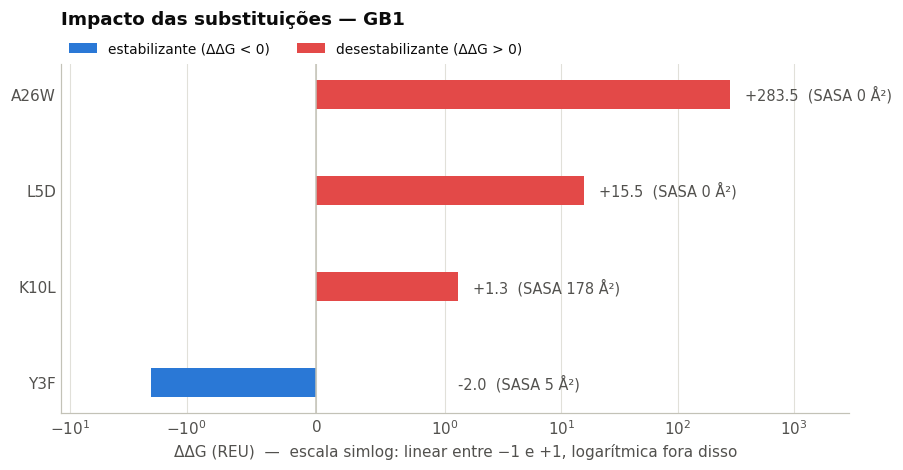

In [ ]:
# Os ΔΔG variam de ~-2 a centenas de REU: eixo SIMLOG (linear perto de zero, log depois),
# para que as variantes pequenas não sumam ao lado do colapso estérico.
dados = ddg.sort_values("ddG")

fig, ax = plt.subplots(figsize=(8.4, 0.62 * len(dados) + 1.9))
ax.barh(dados["variante"], dados["ddG"], height=0.3, linewidth=0,
        color=[COR["favoravel"] if v < 0 else COR["desfavoravel"] for v in dados["ddG"]])
ax.set_xscale("symlog", linthresh=1.0)
for y, (v, s) in enumerate(zip(dados["ddG"], dados["sasa"])):
    # Rótulo sempre à direita: para barras negativas isso cai no espaço vazio
    # depois do zero, evitando colisão com os nomes das variantes.
    x = (v * 1.35 if abs(v) > 1 else v + 0.25) if v >= 0 else 1.3
    ax.text(x, y, f"{v:+.1f}  (SASA {s:.0f} Å²)", va="center", ha="left",
            fontsize=9.5, color=COR["tinta2"])

ax.axvline(0, color=COR["eixo"], linewidth=1.0)
ax.set_xlim(-12, 3000)
ax.set_xlabel("ΔΔG (REU)  —  escala simlog: linear entre −1 e +1, logarítmica fora disso")
ax.set_title("Impacto das substituições — GB1", pad=26)
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.legend(handles=[Patch(facecolor=COR["favoravel"], label="estabilizante (ΔΔG < 0)"),
                   Patch(facecolor=COR["desfavoravel"], label="desestabilizante (ΔΔG > 0)")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
plt.tight_layout(); plt.show()

> 💡 **Quatro substituições, três ordens de grandeza.** Repare que o eixo é **logarítmico fora da
> faixa −1 a +1**: sem isso, tudo que não fosse a variante de maior ΔΔG viraria um traço colado no
> zero. A Seção B.5 abre os quatro casos termo a termo.
>
> **Limites do que acabamos de fazer** (diga isso em qualquer apresentação de ΔΔG calculado):
> uma única réplica de um protocolo estocástico; cadeia principal congelada no relaxamento local;
> sem amostragem de entropia conformacional nem do estado desdobrado; REU não é kcal/mol. Em
> trabalho sério: **≥ 3 réplicas** por variante, reportar média e desvio, e **validar contra dados
> experimentais** (bancos como ProTherm / ThermoMutDB para estabilidade, SKEMPI para interfaces).

## B.5 Por dentro das variantes: de onde vem o ΔΔG?

O ΔΔG é um número só, e um número não explica nada. Para entender **por que** uma substituição
estabiliza ou desestabiliza, abrimos a energia **do resíduo mutado** termo a termo, comparando o
*Matched WT* (**antes**) com o mutante (**depois**). Os dois passaram exatamente pelo mesmo
relaxamento local, então a diferença que sobra é da mutação.

Dois detalhes de leitura, importantes para não tirar conclusão errada:

- Termos de **par** (`fa_atr`, `fa_rep`, `fa_sol`, `fa_elec`, `hbond_*`) são divididos meio a meio
  entre os dois resíduos que interagem. O que um resíduo "perde" aparece em parte nos **vizinhos** —
  por isso olhamos a vizinhança logo em seguida.
- `ref` muda **por definição** quando o aminoácido muda: é a energia de referência de cada tipo de
  resíduo, uma calibração do estado desdobrado, não uma interação física. Não o interprete
  estruturalmente.

In [ ]:
def termos_residuo(p, i):
    """Contribuição (peso x valor bruto) de cada termo da REF2015 para a energia do resíduo i."""
    scorefxn(p)
    emap, w = p.energies().residue_total_energies(i), scorefxn.weights()
    return {str(st).replace("ScoreType.", ""): w[st] * emap[st]
            for st in scorefxn.get_nonzero_weighted_scoretypes()}

termos_mut = {}
for r in resultados:
    pre, pos = termos_residuo(r["pose_wt"], r["i"]), termos_residuo(r["pose_mut"], r["i"])
    t = pd.DataFrame({"termo": list(pre), "antes_WT": list(pre.values()),
                      "depois_mut": [pos[k] for k in pre]})
    t["delta"] = t["depois_mut"] - t["antes_WT"]
    termos_mut[r["variante"]] = t
    print(f"=== {r['variante']}   (energia do resíduo mutado)")
    print(f"    {t['antes_WT'].sum():+.2f}  ->  {t['depois_mut'].sum():+.2f} REU"
          f"   (Δ = {t['delta'].sum():+.2f})")
    print(t[t["delta"].abs() > 0.01].sort_values("delta").round(2).to_string(index=False), "\n")

=== L5D   (energia do resíduo mutado)
    -6.12  ->  +0.87 REU   (Δ = +6.99)
              termo  antes_WT  depois_mut  delta
                ref      1.66       -2.15  -3.81
             fa_rep      1.80        1.21  -0.59
            fa_elec     -1.74       -1.93  -0.19
        lk_ball_wtd      0.02       -0.05  -0.07
       fa_intra_rep      0.02        0.00  -0.01
        rama_prepro     -0.02        0.22   0.23
fa_intra_sol_xover4      0.08        0.43   0.35
            p_aa_pp     -0.11        0.84   0.94
             fa_dun      0.85        2.73   1.88
             fa_atr    -10.68       -7.88   2.79
             fa_sol      1.46        6.92   5.46 

=== A26W   (energia do resíduo mutado)
    -5.30  ->  +113.45 REU   (Δ = +118.76)
              termo  antes_WT  depois_mut  delta
             fa_atr     -6.89      -18.95 -12.06
        lk_ball_wtd     -0.14       -0.73  -0.60
       fa_intra_rep      0.00        0.02   0.02
        rama_prepro     -0.13       -0.05   0.07
      

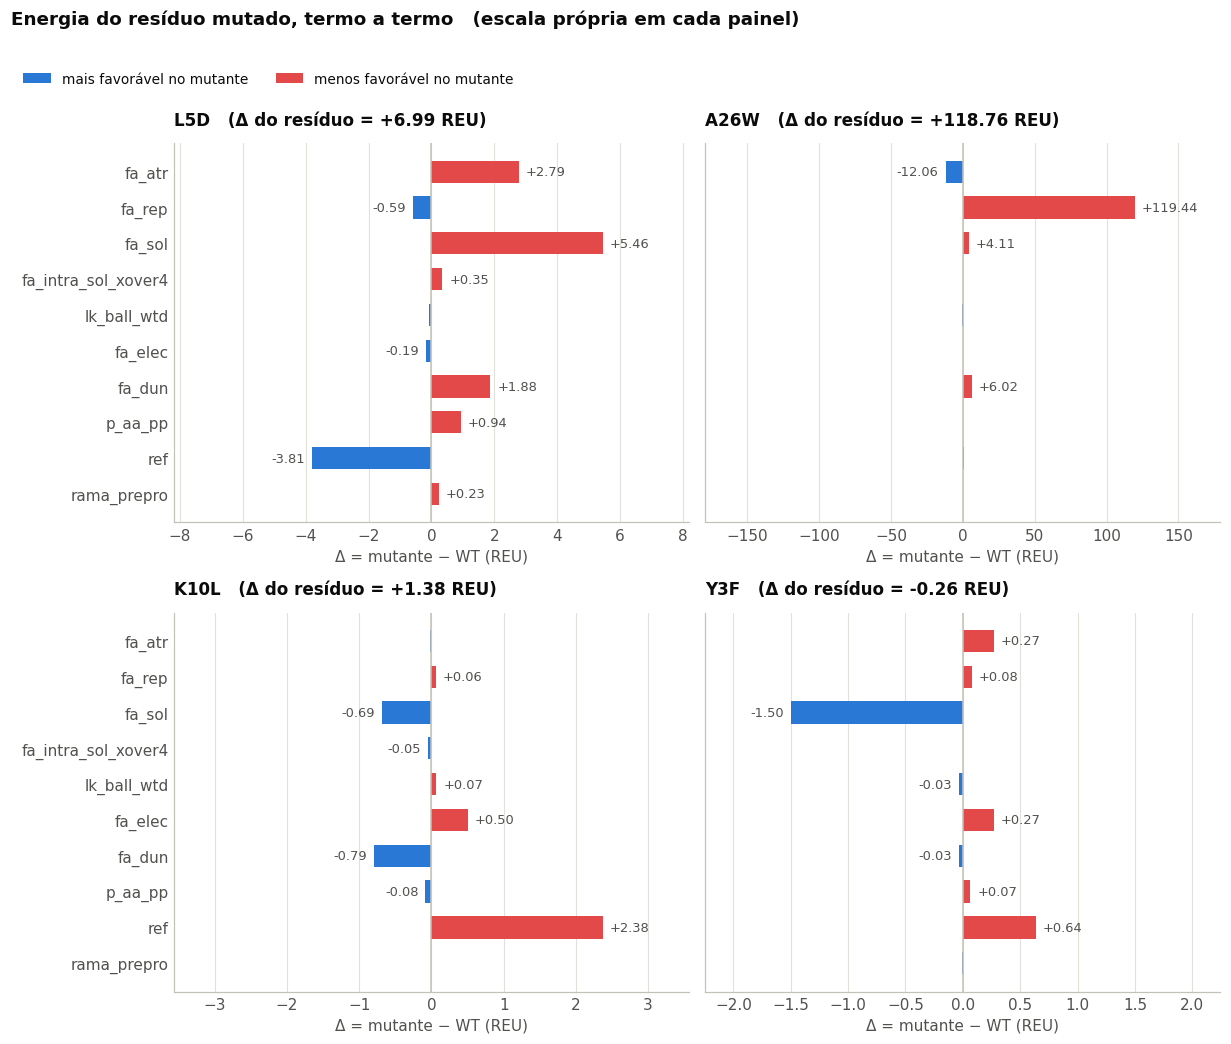

In [ ]:
# Δ por termo no resíduo mutado: um painel por variante, cada um com sua própria escala
termos_vis = [k for k in termos_mut[resultados[0]["variante"]]["termo"]
              if any(abs(t.set_index("termo").at[k, "delta"]) > 0.05 for t in termos_mut.values())]
n = len(termos_mut)
colunas = min(n, 2)
linhas = -(-n // colunas)

fig, eixos = plt.subplots(linhas, colunas, sharey=True, squeeze=False,
                          figsize=(5.6 * colunas, (0.30 * len(termos_vis) + 1.5) * linhas))
painéis = [ax for linha in eixos for ax in linha]
for ax, (variante, t) in zip(painéis, termos_mut.items()):
    d = t.set_index("termo").loc[termos_vis, "delta"]
    faixa = max(d.abs().max(), 0.1)          # escala própria: as magnitudes diferem muito
    ax.barh(termos_vis, d, height=0.62, linewidth=0,
            color=[COR["favoravel"] if v < 0 else COR["desfavoravel"] for v in d])
    for y, v in enumerate(d):
        if abs(v) < faixa * 0.02:
            continue                          # não rotula o que é visualmente zero
        ax.text(v + (faixa * 0.04 if v >= 0 else -faixa * 0.04), y, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8.5, color=COR["tinta2"])
    ax.axvline(0, color=COR["eixo"], linewidth=1.0)
    ax.set_xlim(-faixa * 1.5, faixa * 1.5)
    ax.set_title(f"{variante}   (Δ do resíduo = {t['delta'].sum():+.2f} REU)", fontsize=11)
    ax.set_xlabel("Δ = mutante − WT (REU)")
    ax.xaxis.grid(True); ax.set_axisbelow(True); ax.tick_params(length=0)
for ax in painéis[n:]:
    ax.set_visible(False)
eixos[0][0].invert_yaxis()
fig.legend(handles=[Patch(facecolor=COR["favoravel"], label="mais favorável no mutante"),
                    Patch(facecolor=COR["desfavoravel"], label="menos favorável no mutante")],
           loc="upper left", bbox_to_anchor=(0.005, 1.0), ncol=2, frameon=False)
fig.suptitle("Energia do resíduo mutado, termo a termo   (escala própria em cada painel)",
             x=0.005, ha="left", y=1.05, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### O entorno: quais vizinhos sentiram a mutação?

Como os termos de par são divididos entre os dois resíduos que interagem, metade do efeito de uma
mutação aparece **fora** do resíduo mutado. Somamos, para cada vizinho a até 8 Å, a variação de
energia entre o *Matched WT* e o mutante, e apontamos o termo que mais mudou em cada um.

In [ ]:
def vizinhos(p, i, raio=8.0):
    """Índices Rosetta dos resíduos a até `raio` Å do resíduo i (sem incluir i)."""
    mascara = NeighborhoodResidueSelector(ResidueIndexSelector(str(i)), raio, False).apply(p)
    return [k for k in range(1, p.total_residue() + 1) if mascara[k]]

vizinhanca = {}
for r in resultados:
    p_wt, p_mut, i = r["pose_wt"], r["pose_mut"], r["i"]
    linhas = []
    for k in vizinhos(p_wt, i):
        pre, pos = termos_residuo(p_wt, k), termos_residuo(p_mut, k)
        deltas = {t: pos[t] - pre[t] for t in pre}
        chave = max(deltas, key=lambda t: abs(deltas[t]))
        linhas.append({"vizinho": f"{p_wt.residue(k).name1()}{info_gb1.number(k)}",
                       "delta_total": sum(deltas.values()),
                       "termo_que_mais_mudou": chave, "delta_termo": deltas[chave]})
    viz = pd.DataFrame(linhas)
    viz = viz.reindex(viz["delta_total"].abs().sort_values(ascending=False).index)
    vizinhanca[r["variante"]] = viz

    d_res = termos_mut[r["variante"]]["delta"].sum()
    d_viz = viz["delta_total"].sum()
    print(f"=== {r['variante']}   ({len(viz)} vizinhos a 8 Å)")
    print(f"    Δ no resíduo mutado : {d_res:+.2f} REU")
    print(f"    Δ somado na vizinhança: {d_viz:+.2f} REU"
          f"   ({abs(d_viz) / max(abs(d_res) + abs(d_viz), 1e-9):.0%} do efeito total)")
    print(viz.head(6).round(2).to_string(index=False), "\n")

=== L5D   (16 vizinhos a 8 Å)
    Δ no resíduo mutado : +6.99 REU
    Δ somado na vizinhança: +7.85 REU   (53% do efeito total)
vizinho  delta_total termo_que_mais_mudou  delta_termo
    F30         1.89               fa_sol         1.18
     I6         1.19               fa_sol         0.54
     L7         1.19               fa_sol         1.00
    F52         1.04               fa_sol         0.67
    V54         0.58               fa_sol         0.45
    Y33         0.49               fa_atr         0.35 

=== A26W   (15 vizinhos a 8 Å)
    Δ no resíduo mutado : +118.76 REU
    Δ somado na vizinhança: +159.69 REU   (57% do efeito total)
vizinho  delta_total termo_que_mais_mudou  delta_termo
    A20        60.74               fa_rep        61.97
     M1        34.95               fa_rep        25.00
     Y3        23.11               fa_rep        15.94
    A23        12.54               fa_rep        13.34
    T18        11.60               fa_rep         8.51
    D22         6.89  

In [ ]:
def ver_sitio_wt_mut(p_wt, p_mut, i, raio=8.0, largura=740, altura=460):
    """Sítio da mutação: WT em azul e mutante em laranja, sobrepostos."""
    info = p_wt.pdb_info()
    cadeia, num = info.chain(i), info.number(i)
    viz = [info.number(k) for k in vizinhos(p_wt, i, raio)]
    vis = py3Dmol.view(width=largura, height=altura)
    for p in (p_wt, p_mut):
        vis.addModel(pose_para_pdb(p), "pdb")
    vis.setStyle({"model": 0}, {"cartoon": {"color": "#d8d8d4", "opacity": 0.7}})
    vis.setStyle({"model": 1}, {})
    for m, cor in ((0, "blueCarbon"), (1, "orangeCarbon")):
        vis.addStyle({"model": m, "chain": cadeia, "resi": viz},
                     {"stick": {"colorscheme": cor, "radius": 0.1}})
        vis.addStyle({"model": m, "chain": cadeia, "resi": num},
                     {"stick": {"colorscheme": cor, "radius": 0.28}})
    vis.addResLabels({"model": 1, "chain": cadeia, "resi": num},
                     {"fontSize": 12, "backgroundOpacity": 0.7})
    vis.setBackgroundColor("white")
    vis.zoomTo({"model": 0, "chain": cadeia, "resi": num})
    return vis.show()


for r in resultados:
    print(f"{r['variante']}   azul = WT  |  laranja = mutante   "
          f"(bastões grossos = resíduo mutado; finos = vizinhos a 8 Å)")
    ver_sitio_wt_mut(r["pose_wt"], r["pose_mut"], r["i"])

L5D   azul = WT  |  laranja = mutante   (bastões grossos = resíduo mutado; finos = vizinhos a 8 Å)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

A26W   azul = WT  |  laranja = mutante   (bastões grossos = resíduo mutado; finos = vizinhos a 8 Å)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

K10L   azul = WT  |  laranja = mutante   (bastões grossos = resíduo mutado; finos = vizinhos a 8 Å)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Y3F   azul = WT  |  laranja = mutante   (bastões grossos = resíduo mutado; finos = vizinhos a 8 Å)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

> 💡 **Primeiro, o que a SASA estava medindo.** Ela é a área da superfície do resíduo que uma
> esfera de 1,4 Å, do tamanho de uma molécula de água, alcança ao rolar sobre a proteína. SASA
> ≈ 0 significa **enterrado**, sem contato com o solvente; SASA alta significa **exposto**.
>
> Agora compare com o gráfico anterior: **SASA baixa não prevê o sinal do ΔΔG**. L5D, A26W e Y3F
> estão todas enterradas, e os resultados foram de centenas de REU a −2 REU. Estar enterrado
> **amplifica** o efeito de uma substituição, para os dois lados — o que decide o sinal é o que a
> nova cadeia lateral faz naquele ambiente. É isso que a decomposição mostra:
>
> **Cada variante é mais influenciada por um termo diferente, e é isso que conta a história.**
>
> - **L5D — `fa_sol` (solvatação).** Uma leucina apolar vira um aspartato **carregado** num ponto
>   sem contato com o solvente. O `fa_sol` penaliza enterrar um grupo polar, porque ele precisa
>   abandonar sua camada de água, e aqui dispara. Junto vem o `fa_atr`, que piora: os contatos de
>   van der Waals que a cadeia lateral maior e apolar da leucina fazia com o núcleo desaparecem — e
>   parte dessa perda aparece **nos vizinhos**.
> - **A26W — `fa_rep` (repulsão estérica).** A alanina tem a menor cadeia lateral que existe
>   depois da glicina; o triptofano tem a maior. Não há espaço, os átomos se sobrepõem e o `fa_rep`
>   explode. Repare que o `fa_atr` até **melhora** (mais átomos, mais contato), mas é irrelevante
>   diante da repulsão. Lição de método: o *repacking* a 8 Å só escolhe **rotâmeros** — nenhuma
>   escolha de rotâmero resolve um choque desse tamanho, porque seria preciso **mover a cadeia
>   principal**, e ela está congelada.
> - **K10L — `ref` (energia de referência).** Na posição mais exposta da proteína, os termos
>   **físicos** quase não mudam: o solvente continua ali, não há núcleo para perturbar. O que
>   domina o ΔΔG é o `ref`, que é **calibração do estado desdobrado**, não interação. Ou seja: o
>   número é pequeno e vem de um termo que não descreve estrutura.
> - **Y3F — `fa_sol`, com o sinal invertido.** A tirosina perde apenas a **hidroxila** e vira
>   fenilalanina; o anel aromático, que faz o grosso do empacotamento, continua lá. Sai justamente
>   o grupo polar que estava enterrado pagando dessolvatação, e o `fa_sol` **melhora**. Compare com
>   L5D: **o mesmo termo** explica as duas, com sinais opostos.
>
> ⚠️ **K10L expõe um limite importante do método.** Proteínas naturais evitam hidrofóbicos na
> superfície, mas não por causa da estabilidade da estrutura dobrada: é por **solubilidade e
> agregação**. A REF2015 pontua **uma conformação isolada** e não modela nem agregação, nem o
> estado desdobrado, nem a concentração. Um ΔΔG próximo de zero aqui **não** significa que a
> mutação é inofensiva na bancada.
>
> **Note a assimetria das magnitudes.** Desestabilizar é fácil e rende números enormes; estabilizar
> uma estrutura **já relaxada globalmente** rende, na melhor das hipóteses, poucos REU. Essa
> assimetria é real e aparece também nos experimentos.
>
> **Compare sempre o Δ do resíduo com o Δ da vizinhança.** Quando boa parte do efeito está nos
> vizinhos, a mutação age **reorganizando o entorno**, não só pelo que a nova cadeia lateral faz
> sozinha.
>
> ⚠️ **Y3F é uma previsão, não um fato medido.** O protocolo não amostra o estado desdobrado nem a
> entropia, e a hidroxila da tirosina pode fazer uma ligação de hidrogênio estruturalmente
> importante que este cálculo de réplica única subestima. Um ΔΔG de −2 REU é uma **hipótese
> testável** — o passo seguinte é o experimento, não a conclusão.

---
---
# Parte C — Interface proteína–proteína

## C.1 O conceito

Nas Partes A e B trabalhamos com **uma cadeia de cada vez**. Agora o objeto de estudo é o
**contato entre duas proteínas**: o que mantém um complexo unido, e como medir isso.

O caso é o de um projeto de *design*: três **ligantes proteicos de novo** (*binders*) de 65
resíduos, desenhados por computador contra o **mesmo alvo** de 221 resíduos, dobrados pelo
AlphaFold2 e relaxados no Rosetta. Em cada arquivo, a cadeia **A** é o binder e a cadeia **B** é o
alvo. Um pipeline de design produz centenas de candidatos como esses, e alguém precisa decidir
quais valem o custo da síntese e do ensaio.

O `InterfaceAnalyzerMover` separa os dois parceiros, **reempacota cada um isoladamente** e compara
com o complexo. É a diferença entre os dois estados que vira energia de ligação. As métricas:

| Métrica | Direção | O que significa |
|---|---|---|
| **dG_separated** | mais negativo é melhor | energia de ligação (REU): complexo − parceiros separados |
| **dSASA** | — | área (Å²) enterrada ao formar a interface: o "tamanho" do contato |
| **H-bonds na interface** | mais é melhor | ligações de hidrogênio que atravessam o contato |
| **Insatisfeitos** | menos é melhor | doadores/aceptores enterrados que ficaram **sem par** — custo energético real |
| **sc_value** | mais alto é melhor | complementaridade de forma, de 0 a 1 |
| **packstat** | mais alto é melhor | qualidade do empacotamento na interface, de 0 a 1 |

> 📂 **Os três arquivos `.pdb` são entregues com a aula.** No Colab, a célula de carregamento
> abre o seletor de envio caso eles ainda não estejam na sessão — basta escolher os três. Para
> usar um complexo seu, aponte `PADRAO_MODELOS` para ele e ajuste a especificação de cadeias.

In [ ]:
import glob, re, urllib.request

PADRAO_MODELOS = "binder*.pdb"          # como os arquivos da aula se chamam
REPO_MODELOS = "https://raw.githubusercontent.com/jsartori12/SBBS2026-PyRosetta/main"
ARQUIVOS_DA_AULA = [
    "binderEC_65_job11_146_dldesign_1_af2pred_relaxed.pdb",
    "binderEC_65_job52_255_dldesign_3_af2pred_relaxed.pdb",
    "binderEC_65_job83_151_dldesign_1_af2pred_relaxed.pdb",
]


def arquivos_dos_modelos():
    """Garante os PDBs da aula nesta sessão.

    Três tentativas, em ordem: (1) usar os arquivos que já estão na pasta;
    (2) baixá-los do repositório da aula — no Colab esse download sai do
    datacenter do Google, não da sua rede; (3) abrir o seletor de upload.
    """
    if sorted(glob.glob(PADRAO_MODELOS)):
        return sorted(glob.glob(PADRAO_MODELOS))

    print("Baixando os modelos da aula...")
    for arquivo in ARQUIVOS_DA_AULA:
        try:
            urllib.request.urlretrieve(f"{REPO_MODELOS}/{arquivo}", arquivo)
        except Exception as erro:
            print(f"  não consegui baixar {arquivo}: {erro}")
    if sorted(glob.glob(PADRAO_MODELOS)):
        return sorted(glob.glob(PADRAO_MODELOS))

    try:
        from google.colab import files     # existe só dentro do Colab
    except ImportError:
        raise FileNotFoundError(
            f"Nenhum arquivo {PADRAO_MODELOS} nesta pasta e o download falhou. "
            "Copie os PDBs da aula para cá.")
    print("Download indisponível. Envie os três arquivos da aula:")
    files.upload()                         # abre o seletor de arquivos do navegador
    return sorted(glob.glob(PADRAO_MODELOS))


def nome_curto(caminho):
    """binderEC_65_job11_146_dldesign_1_af2pred_relaxed.pdb  ->  job11_146"""
    achado = re.search(r"job\d+_\d+", caminho)
    return achado.group(0) if achado else caminho.split("/")[-1][:-4]


caminhos_binder = {nome_curto(c): c for c in arquivos_dos_modelos()}
print(f"{len(caminhos_binder)} modelos disponíveis:")
for nome, caminho in caminhos_binder.items():
    print(f"  {nome}  <-  {caminho}")

In [ ]:
# Sem cleanATOM: são modelos, não PDBs experimentais — não há água, ligante nem confôrmero alterno.
poses_binder = {nome: pyrosetta.pose_from_file(caminho)
                for nome, caminho in caminhos_binder.items()}

for nome, modelo in poses_binder.items():
    d = modelo.pdb_info()
    cadeias = sorted({d.chain(i) for i in range(1, modelo.total_residue() + 1)})
    print(f"{nome}: {modelo.total_residue()} resíduos, cadeias {cadeias}, "
          f"score {scorefxn(modelo):+.1f} REU")

print("\nBinder (cadeia A) de cada modelo:")
for nome, modelo in poses_binder.items():
    print(f"  {nome}  {modelo.split_by_chain(1).sequence()}")

> 💡 **Repare nos scores totais: todos fortemente negativos.** Compare com a estrutura
> recém-importada da Seção A.3. Esses modelos passaram por relaxamento no pipeline de design, e é
> por isso que podemos analisar a interface direto — a lição da Parte A já foi aplicada neles.

## C.2 Uma interface em detalhe

Antes de comparar os três, vamos abrir **um** deles por inteiro. Troque `MODELO_EXEMPLO` para
repetir a análise em qualquer um dos outros.

In [ ]:
# ⏱️ ~5 s (o mover reempacota os parceiros separados)
MODELO_EXEMPLO = "job11_146"          # troque por "job52_255" ou "job83_151"

from pyrosetta.rosetta.protocols.analysis import InterfaceAnalyzerMover


def analisador_de_interface(especificacao):
    """InterfaceAnalyzerMover a partir de uma especificação como "A_B".

    Em versões recentes do PyRosetta o construtor deixou de aceitar a string
    diretamente e passou a exigir um objeto `DockingPartners`. O `try/except`
    mantém o notebook funcionando nas duas gerações da API.
    """
    try:
        return InterfaceAnalyzerMover(especificacao)
    except TypeError:
        from pyrosetta.rosetta.core.pose import DockingPartners
        return InterfaceAnalyzerMover(DockingPartners.docking_partners_from_string(especificacao))


ia = analisador_de_interface("A_B")   # cadeia A (binder) contra cadeia B (alvo)
ia.set_scorefunction(scorefxn)
ia.set_pack_separated(True)           # reempacota cada parceiro sozinho (comparação justa)
ia.set_compute_packstat(True)
ia.set_compute_interface_sc(True)

pose_exemplo = poses_binder[MODELO_EXEMPLO].clone()   # o mover modifica o Pose: sempre em cópia
t0 = time.time()
ia.apply(pose_exemplo)
print(f"{MODELO_EXEMPLO}: análise concluída em {time.time()-t0:.0f} s")

In [ ]:
def _tenta(f, padrao=float("nan")):
    try:
        return f()
    except Exception:
        return padrao

metricas = {
    "dG_separated (REU)":       _tenta(ia.get_interface_dG),
    "dSASA (Å²)":               _tenta(ia.get_interface_delta_sasa),
    "resíduos na interface":    _tenta(ia.get_num_interface_residues),
    "sc_value":                 _tenta(lambda: ia.get_all_data().sc_value),
    "packstat":                 _tenta(ia.get_interface_packstat),
    "H-bonds na interface":     _tenta(lambda: ia.get_all_data().interface_hbonds),
    "doadores/aceptores insatisfeitos": _tenta(ia.get_interface_delta_hbond_unsat),
}
resumo_if = pd.DataFrame({"métrica": list(metricas), "valor": list(metricas.values())})

dg, dsasa = metricas["dG_separated (REU)"], metricas["dSASA (Å²)"]
print(resumo_if.round(2).to_string(index=False))
print(f"\nEficiência da interface: {dg/dsasa*100:.2f} REU por 100 Å² enterrados")

> 💡 **Como ler esses números**
>
> - **dSASA** situa o tamanho do contato. *Binders* de novo costumam enterrar algo entre 1000 e
>   2000 Å² — bem mais que uma interface transiente de sinalização, bem menos que um complexo
>   obrigatório grande.
> - **dG_separated sozinho não basta**: ele cresce com o tamanho do contato. Normalizar por área
>   (a "eficiência" acima) é o que permite comparar interfaces de tamanhos diferentes.
> - **sc_value** distingue um encaixe real de uma justaposição. Valor baixo com dSASA grande é
>   sinal de superfícies que se tocam sem se encaixar.
> - **`resíduos na interface`** conta **os dois lados** do contato. A célula seguinte usa um
>   seletor restrito à cadeia A, e por isso chega a um número bem menor: são só os resíduos **do
>   binder**.
> - **Insatisfeitos** é a métrica mais negligenciada: cada doador ou aceptor de ligação de H
>   enterrado sem parceiro é um custo energético real. Muitos deles indicam interface mal modelada.

### Quais resíduos formam a interface?

In [ ]:
from pyrosetta.rosetta.core.select.residue_selector import (
    ChainSelector, AndResidueSelector, NeighborhoodResidueSelector)

sel_A, sel_B = ChainSelector("A"), ChainSelector("B")   # A = binder, B = alvo
viz_do_alvo = NeighborhoodResidueSelector(sel_B, 8.0, False)
interface_binder = AndResidueSelector(sel_A, viz_do_alvo)

mascara = interface_binder.apply(pose_exemplo)
indices_if = [k for k in range(1, pose_exemplo.total_residue() + 1) if mascara[k]]
d = pose_exemplo.pdb_info()

scorefxn(pose_exemplo)
tabela_if = pd.DataFrame({
    "pdb": [d.number(k) for k in indices_if],
    "aa": [pose_exemplo.residue(k).name1() for k in indices_if],
    "energia": [pose_exemplo.energies().residue_total_energy(k) for k in indices_if],
}).sort_values("pdb")

print(f"{len(indices_if)} dos 65 resíduos do binder estão a menos de 8 Å do alvo\n")
print("Resíduos de interface do binder:", "".join(tabela_if["aa"]))
print("\nOs de energia mais favorável:")
print(tabela_if.nsmallest(8, "energia").to_string(index=False))

### Onde fica a interface na estrutura?

A tabela acima diz **quais** resíduos formam o contato; ela não diz **onde**. Este bloco desenha a
superfície do alvo e pinta de laranja a área que o binder cobre — a "pegada" do contato — com os
resíduos do binder que a tocam em bastões.

In [ ]:
def ver_interface(modelo, cadeia_binder="A", cadeia_alvo="B", raio=8.0,
                  superficie=True, largura=760, altura=480):
    """Mostra onde está a interface: o binder em cartoon, o alvo como superfície.

    Os resíduos de contato do binder aparecem em bastões; a área que eles tocam no
    alvo fica destacada na superfície. Passe `superficie=False` se ficar lento.
    """
    info = modelo.pdb_info()
    sel_binder, sel_alvo = ChainSelector(cadeia_binder), ChainSelector(cadeia_alvo)
    de_cada_lado = {
        cadeia_binder: AndResidueSelector(
            sel_binder, NeighborhoodResidueSelector(sel_alvo, raio, False)).apply(modelo),
        cadeia_alvo: AndResidueSelector(
            sel_alvo, NeighborhoodResidueSelector(sel_binder, raio, False)).apply(modelo),
    }
    numeros = {cadeia: [str(info.number(i)) for i in range(1, modelo.total_residue() + 1)
                        if mascara[i] and info.chain(i) == cadeia]
               for cadeia, mascara in de_cada_lado.items()}

    vis = py3Dmol.view(width=largura, height=altura)
    vis.addModel(pose_para_pdb(modelo), "pdb")
    vis.setStyle({"chain": cadeia_alvo}, {"cartoon": {"color": "#cfcec7"}})
    vis.setStyle({"chain": cadeia_binder}, {"cartoon": {"color": "#2a78d6"}})

    if superficie:   # a superfície do alvo mostra o "buraco" onde o binder se encaixa
        vis.addSurface(py3Dmol.VDW, {"opacity": 0.70, "color": "#e4e3dc"},
                       {"chain": cadeia_alvo})
        vis.addSurface(py3Dmol.VDW, {"opacity": 0.92, "color": "#eb6834"},
                       {"chain": cadeia_alvo, "resi": numeros[cadeia_alvo]})

    vis.addStyle({"chain": cadeia_binder, "resi": numeros[cadeia_binder]},
                 {"stick": {"colorscheme": "blueCarbon", "radius": 0.21}})
    vis.setBackgroundColor("white")
    vis.zoomTo({"chain": cadeia_binder})

    print(f"Binder (cadeia {cadeia_binder}): {len(numeros[cadeia_binder])} resíduos de contato "
          f"-> {', '.join(numeros[cadeia_binder])}")
    print(f"Alvo   (cadeia {cadeia_alvo}): {len(numeros[cadeia_alvo])} resíduos de contato "
          f"-> {', '.join(numeros[cadeia_alvo])}")
    return vis.show()


# Azul = binder, bastões = seus resíduos de contato. Laranja na superfície = a pegada no alvo.
ver_interface(pose_exemplo)

## C.3 Comparando os três binders

A análise acima vale para um modelo. O uso real é **comparativo**: rodar o mesmo protocolo nos
três candidatos e olhar para quatro métricas lado a lado — **dG_separated**, **H-bonds**,
**insatisfeitos** e **sc_value**.

In [ ]:
# ⏱️ ~10 s no total (3 modelos, ~3 s cada)
def analisa_interface(modelo, especificacao="A_B"):
    """Roda o InterfaceAnalyzerMover e devolve as métricas em um dicionário."""
    ia = analisador_de_interface(especificacao)
    ia.set_scorefunction(scorefxn)
    ia.set_pack_separated(True)        # reempacota cada parceiro sozinho (comparação justa)
    ia.set_compute_packstat(True)
    ia.set_compute_interface_sc(True)

    copia = modelo.clone()             # o mover modifica o Pose: sempre em uma cópia
    ia.apply(copia)
    dados = ia.get_all_data()
    dg = ia.get_interface_dG()
    dsasa = ia.get_interface_delta_sasa()
    return {"dG_separated": dg,
            "hbonds": dados.interface_hbonds,
            "insatisfeitos": ia.get_interface_delta_hbond_unsat(),
            "sc_value": dados.sc_value,
            "dSASA": dsasa,
            "dG_por_100A2": dg / dsasa * 100,
            "res_interface": ia.get_num_interface_residues()}


binders = pd.DataFrame([{"binder": nome, **analisa_interface(modelo)}
                        for nome, modelo in poses_binder.items()]).set_index("binder")

print(binders.round(2).to_string())

In [ ]:
# Os três binders lado a lado, em uma figura só. Cada métrica tem seu próprio painel porque as
# escalas não são comparáveis: REU, duas contagens e um índice de 0 a 1 em um eixo y comum
# achatariam o sc_value até virar um traço.
METRICAS = [("dG_separated",  "dG_separated",         "REU · mais negativo é melhor", "{:+.1f}"),
            ("hbonds",        "H-bonds na interface", "contagem · mais é melhor",     "{:.0f}"),
            ("insatisfeitos", "Insatisfeitos",        "contagem · menos é melhor",    "{:.0f}"),
            ("sc_value",      "sc_value",             "0 a 1 · mais alto é melhor",   "{:.3f}")]

ordem = list(binders.index)                        # a mesma ordem em todos os painéis
rotulos = [nome.split("_")[0] for nome in ordem]   # job11, job52, job83
CORES_BINDER = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, eixos = plt.subplots(1, 4, figsize=(13.0, 4.1))
for ax, (coluna, titulo, direcao, formato) in zip(eixos, METRICAS):
    v = binders.loc[ordem, coluna]
    ax.bar(rotulos, v, width=0.42, linewidth=0, color=CORES_BINDER, zorder=3)

    # a escala vai do zero até o extremo: nada de espaço vazio do outro lado do eixo
    folga = max(abs(v.max()), abs(v.min())) * 0.22
    for x, valor in enumerate(v):
        ax.text(x, valor + (folga * 0.16 if valor >= 0 else -folga * 0.16), formato.format(valor),
                ha="center", va="bottom" if valor >= 0 else "top",
                fontsize=10, color=COR["tinta2"], zorder=4)
    ax.set_ylim(0 if v.min() >= 0 else v.min() - folga,
                0 if v.max() <= 0 else v.max() + folga)
    ax.axhline(0, color=COR["eixo"], linewidth=1.0, zorder=2)

    ax.set_title(titulo, fontsize=11.5, pad=26)
    ax.text(0, 1.045, direcao, transform=ax.transAxes, fontsize=8.8, color=COR["suave"])
    ax.yaxis.grid(True, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.tick_params(axis="x", labelsize=10)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_visible(False)

fig.suptitle("Três binders de novo contra o mesmo alvo", x=0.004, ha="left", y=1.06,
             fontsize=13, fontweight="bold")
plt.tight_layout(w_pad=2.4)
plt.show()

### O pipeline já havia calculado isso — reproduzimos?

Os três arquivos trazem, no rodapé, as linhas `ifa_*`: as métricas que o **próprio pipeline de
design** calculou com o `InterfaceAnalyzer`, em outra versão do Rosetta. É uma oportunidade rara —
podemos checar nossos números contra os de uma execução independente do mesmo protocolo.

In [ ]:
def ifa_gravado(caminho):
    """Lê as linhas ifa_* que o pipeline de design deixou no final do arquivo PDB."""
    campos = {}
    for linha in open(caminho):
        if linha.startswith("ifa_"):
            chave, _, valor = linha.strip().partition(" ")
            try:
                campos[chave] = float(valor)
            except ValueError:
                pass
    return campos


EQUIVALENTES = {"dG_separated": "ifa_dG_separated", "hbonds": "ifa_hbonds_int",
                "insatisfeitos": "ifa_delta_unsatHbonds", "sc_value": "ifa_sc_value"}

comparacao = pd.DataFrame([
    {"métrica": metrica, "binder": nome,
     "agora": binders.at[nome, metrica],
     "pipeline": ifa_gravado(caminhos_binder[nome]).get(chave)}
    for metrica, chave in EQUIVALENTES.items() for nome in binders.index
])
comparacao["diferença"] = comparacao["pipeline"] - comparacao["agora"]

print(comparacao.round(3).to_string(index=False))

In [ ]:
# Mesma métrica, duas execuções: a nossa e a do pipeline. Um painel por métrica.
fig, eixos = plt.subplots(2, 2, figsize=(12.4, 5.8))
for ax, (coluna, titulo, direcao, formato) in zip(eixos.ravel(), METRICAS):
    sub = comparacao[comparacao["métrica"] == coluna].set_index("binder").loc[ordem]
    y = range(len(ordem))
    for deslocamento, serie, cor in ((0.17, "agora", "serie1"), (-0.17, "pipeline", "serie2")):
        ax.barh([k + deslocamento for k in y], sub[serie], height=0.26, linewidth=0, color=COR[cor])
    faixa = max(sub[["agora", "pipeline"]].abs().max().max(), 1e-9)
    for k in y:
        for deslocamento, serie in ((0.17, "agora"), (-0.17, "pipeline")):
            valor = sub[serie].iloc[k]
            ax.text(valor + (faixa * 0.03 if valor >= 0 else -faixa * 0.03), k + deslocamento,
                    formato.format(valor), va="center", ha="left" if valor >= 0 else "right",
                    fontsize=8.5, color=COR["tinta2"])
    ax.set_yticks(list(y))
    ax.set_yticklabels(ordem)
    ax.set_xlim(min(0, sub[["agora", "pipeline"]].min().min() * 1.5),
                max(0, sub[["agora", "pipeline"]].max().max() * 1.5))
    ax.axvline(0, color=COR["eixo"], linewidth=1.0)
    ax.set_title(f"{titulo}\n{direcao}", fontsize=10.5)
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

fig.legend(handles=[Patch(facecolor=COR["serie1"], label="nossa execução, agora"),
                    Patch(facecolor=COR["serie2"], label="pipeline de design (outra versão)")],
           loc="upper left", bbox_to_anchor=(0.004, 1.0), ncol=2, frameon=False)
fig.suptitle("A mesma interface, dois cálculos independentes", x=0.004, ha="left", y=1.08,
             fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Os três complexos em 3D: alvo (cadeia B) e binder (cadeia A) em cores diferentes
for nome, modelo in poses_binder.items():
    print(f"--- {nome}")
    ver(modelo, largura=720, altura=380)

> 💡 **O que as quatro métricas dizem — e no que elas discordam.**
>
> **Primeiro: nenhum dos três binders tem o melhor valor nas quatro.** Essa é a observação
> importante. O `job52` tem o `dG_separated` mais favorável; o `job83` tem o melhor `sc_value` e
> o menor número de insatisfeitos, mas com a **menor** interface das três; o `job11` faz mais
> ligações de hidrogênio que os outros dois e, ao mesmo tempo, deixa **mais** doadores e aceptores
> sem parceiro. Não existe um vencedor por consenso.
>
> **dG_separated cresce com o tamanho do contato.** Por isso a tabela traz `dG_por_100A2`:
> dividido pela área enterrada, o contraste entre os três encolhe muito. Comparar `dG_separated`
> bruto entre interfaces de tamanhos diferentes premia simplesmente a maior.
>
> **Insatisfeitos é a métrica mais negligenciada e a mais reveladora.** Cada doador ou aceptor
> enterrado sem parceiro é um custo energético real que o `dG_separated` já contabilizou, mas de
> forma diluída no total. Uma interface com dG favorável e muitos insatisfeitos costuma indicar
> um contato modelado às pressas, não um encaixe bom.
>
> ⚠️ **Nenhuma dessas quatro métricas é afinidade.** São descritores de **uma** conformação, com
> cadeia principal congelada, sem entropia conformacional, sem o estado não ligado, sem solvente
> explícito. Elas servem para **filtrar** candidatos — descartar o que está claramente ruim — e
> não para **ordenar** os bons. Em campanhas reais de *binders* de novo, dezenas de designs que
> passam pelos filtros vão para a bancada, e a taxa de acerto experimental continua baixa.
>
> **A comparação com o pipeline separa o que é reprodutível do que não é.** O `sc_value` bate na
> terceira casa decimal e a contagem de ligações de hidrogênio é **idêntica** nos três: são
> medidas geométricas, determinadas pelas coordenadas. Os insatisfeitos variam pouco. Já o
> `dG_separated` difere em **12 a 14 REU** — porque calcular a referência "parceiros separados"
> exige **reempacotar** cada lado, e o *repacking* é estocástico e sensível à versão do Rosetta e
> às *flags*.
>
> E não é preciso ir a outra versão do Rosetta para ver isso: compare o `dG_separated` do
> `job11_146` na tabela da Seção C.3 com o que a Seção C.2 imprimiu para o **mesmo modelo**. Mesmo
> protocolo, mesma sessão, mesma *seed* — e os números diferem na primeira casa decimal, porque o
> reempacotamento consumiu números aleatórios diferentes. Já `sc_value`, dSASA e as contagens de
> ligação de hidrogênio são idênticas nas duas seções.
>
> Repare, por fim, que o desvio em relação ao pipeline tem **o mesmo sinal e magnitude parecida
> nos três**: é um desvio
> **sistemático**, não ruído. Por isso a ordem relativa sobrevive, e um viés constante se cancela
> na comparação. A lição prática: o **valor absoluto** de `dG_separated` não é transferível entre
> execuções — só a comparação entre modelos avaliados **na mesma execução, com as mesmas flags**.

---
---
# Exercícios

**1. Numeração.** Escreva `pdb_para_rosetta(pose, cadeia, numero)` que converta a numeração e
**lance uma exceção informativa** se o resíduo não existir, em vez de devolver `0` silenciosamente.

**2. Enterrado × exposto.** Calcule a SASA da proteína E minimizada (`pose_min`) e escolha a
posição mais enterrada e a mais exposta. Rode `calcular_ddg` para a substituição a alanina nas
duas. O contraste observado em GB1 se repete?

**3. Quantas réplicas?** Rode `calcular_ddg` **cinco vezes** para a mesma variante de GB1, mas
remova `-constant_seed` do `init()` antes (ou reinicie a sessão sem ele). Qual o desvio-padrão do
ΔΔG? Com base nele, qual a menor diferença de ΔΔG que você confiaria em reportar?

**4. O raio importa.** Repita um ΔΔG com `raio = 4, 6, 8, 12` Å. A partir de que raio o valor
estabiliza? Qual o custo em tempo?

**5. Interface.** Rode a análise da Seção C.2 nos outros dois binders trocando `MODELO_EXEMPLO`.
Os resíduos de contato do binder mudam de posição ao longo da sequência? Depois compare o
`dG_separated` normalizado por dSASA dos três com o de um complexo natural à sua escolha no PDB.
O que a comparação permite — e o que não permite — concluir?

**6. Procure você mesmo uma estabilizante.** Varra uma posição enterrada da GB1 contra os 19
aminoácidos com `calcular_ddg` e ordene os ΔΔG. Quantas substituições ficam abaixo de zero? Compare
com o número de desestabilizantes: o que essa assimetria diz sobre proteínas naturais?

**7. O que o experimento diz.** Wunderlich & Schmid (2006) selecionaram variantes de GB1 mais
estáveis por evolução *in vitro*, entre elas E15V, T16L, T18I e N37L. Rode `calcular_ddg` para as
quatro. O Rosetta reproduz o sinal? Use a decomposição da Seção B.5 para investigar uma divergência
— e lembre que o protocolo congela a cadeia principal e ignora o estado desdobrado.

In [ ]:
# Espaço para os exercícios

---
# Resumo

1. **`Pose` é o estado do sistema**, não só coordenadas. Operações o modificam *in place* —
   `clone()` antes de mexer.
2. **Numeração Rosetta é contínua de 1 a N**, ignora cadeias e lacunas. Converta com `pdb2pose` no
   momento do uso e trate o retorno `0`.
3. **Score dá REU, não kcal/mol**, e o valor absoluto diz pouco. O que importa são **diferenças
   entre poses equivalentes**. Decomponha por termo e por resíduo para saber de onde vem o número.
4. **Minimize antes de comparar.** Energia sem RMSD ao lado é meia informação.
5. **ΔΔG exige relaxamento local + *Matched WT*.** Relaxamento global afoga um sinal de 1–3 REU em
   ruído de centenas de REU.
6. **`MoveMap` controla a minimização; `TaskFactory` controla o repacking.** Confundir os dois é a
   diferença entre um ΔΔG confiável e um número aleatório.
7. **Interface: nunca leia `dG_separated` sozinho.** Combine com dSASA, `sc_value` e insatisfeitos.
8. **Todo número calculado precisa de validação experimental.** O PyRosetta gera hipóteses
   quantitativas e prioriza experimentos — não os substitui.

---

### Referências

- CHAUDHURY, S.; LYSKOV, S.; GRAY, J. J. PyRosetta: a script-based interface for implementing
  molecular modeling algorithms using Rosetta. *Bioinformatics*, v. 26, n. 5, p. 689–691, 2010.
- ALFORD, R. F. *et al.* The Rosetta all-atom energy function for macromolecular modeling and
  design. *J. Chem. Theory Comput.*, v. 13, n. 6, p. 3031–3048, 2017. *(REF2015)*
- TYKA, M. D. *et al.* Alternate states of proteins revealed by detailed energy landscape mapping.
  *J. Mol. Biol.*, v. 405, n. 2, p. 607–618, 2011. *(FastRelax)*
- STRANGES, P. B.; KUHLMAN, B. A comparison of successful and failed protein interface designs.
  *Protein Science*, v. 22, n. 1, p. 74–82, 2013. *(métricas de interface)*
- MODIS, Y. *et al.* A ligand-binding pocket in the dengue virus envelope glycoprotein. *PNAS*,
  v. 100, n. 12, p. 6986–6991, 2003. *(1OAN)*
- GALLAGHER, T. *et al.* Two crystal structures of the B1 immunoglobulin-binding domain of
  streptococcal protein G. *Biochemistry*, v. 33, n. 15, p. 4721–4729, 1994. *(1PGA)*
- WUNDERLICH, M.; SCHMID, F. X. In vitro evolution of a hyperstable Gβ1 variant. *Protein
  Science*, v. 15, n. 6, p. 1525–1534, 2006. *(mutações estabilizantes de GB1)*
- MACHADO, L.; SARTORI, J. *The PyRosetta Cookbook for Biomancers*, 2026.
- <https://docs.rosettacommons.org> · <https://www.pyrosetta.org>